# 11 · 苍穹外卖：数据统计（图形报表）

来源：本地 `讲义.rar / 讲义/day11/苍穹外卖-day11.md` 与 `PPT.rar / PPT/day11-数据统计（图形报表）.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章先用 Apache ECharts 了解图表配置，再实现营业额、用户、订单和销量排名 Top10 四组报表接口。保留27段讲义代码、表格和配图，对照68页PPT；补充、勘误与验收清单独立标注，配图内嵌可离线阅读。

报表的核心不是把数字拼成字符串，而是明确统计口径、时间边界、状态条件和返回结构。前端图表需要稳定的日期轴与数据数组，后端则要保证参数校验、SQL聚合、空数据和权限都正确。

> **重点勘误。** 原代码按天循环查询，存在明显的 N+1 查询；营业额使用 `Double` 可能出现金额精度问题；用户总量的截止时间、订单完成率是否返回比例或百分比需要明确；销量 SQL 按商品名称分组会合并同名商品，且时间字段需要明确表别名。后面分别给出改进方向。


## 本章路线、接口与统计口径（补充）

| 报表 | 接口 | 统计内容 |
| --- | --- | --- |
| 营业额 | `GET /admin/report/turnoverStatistics` | 每日已完成订单金额合计 |
| 用户 | `GET /admin/report/userStatistics` | 每日新增用户与截至当天总用户 |
| 订单 | `GET /admin/report/ordersStatistics` | 每日订单总数、有效订单数和区间完成率 |
| 销量 Top10 | `GET /admin/report/top10` | 时间范围内已完成订单明细销量降序前10 |

### 统一约定

- `begin`、`end` 是日期参数，通常按门店业务时区解释；`begin` 和 `end` 都包含在统计范围内。
- 每日区间可使用半开区间 `[date 00:00, nextDate 00:00)`，避免 `LocalTime.MAX` 的精度和数据库列精度差异。
- 图表没有数据时仍返回完整日期轴，数值用0填充，不能让前端日期和数据数组长度不一致。
- 管理端报表需要管理员权限；统计查询只读，不应修改订单、用户或明细数据。

原讲义用逗号分隔字符串适配课程前端，真实接口也可以返回数组。只要前后端契约一致，就不要在不同接口混用两种格式。


## 课程内容

> **PPT对照：** 第1—3页。

- Apache ECharts
- 营业额统计
- 用户统计
- 订单统计
- 销量排名Top10


功能实现：**数据统计**

**数据统计效果图：**

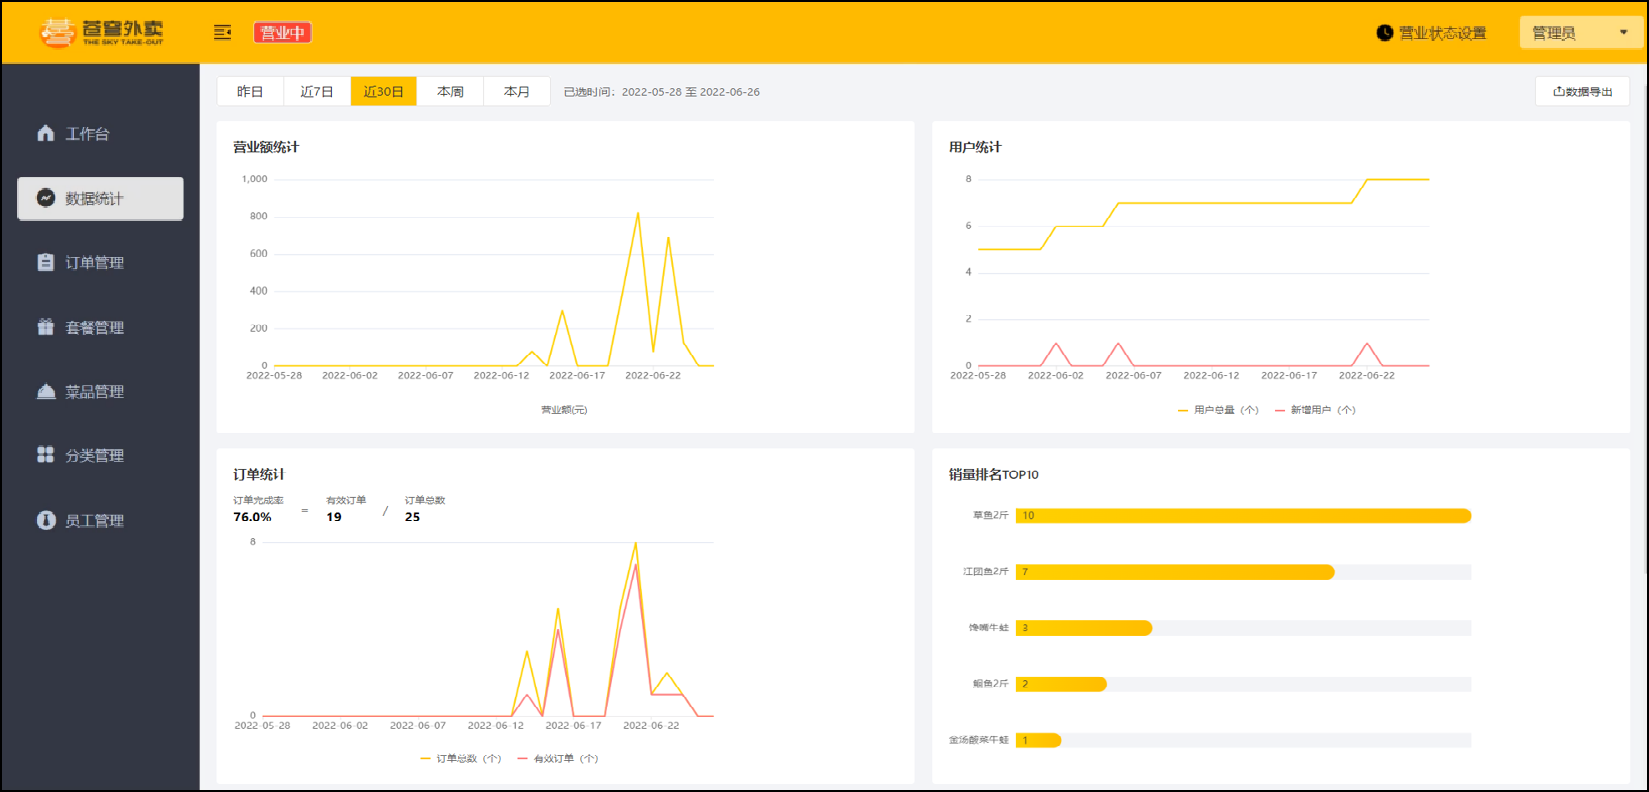


## 1. Apache ECharts

> **PPT对照：** 第4—9页。


### 1.1 介绍

> **PPT对照：** 第5—6页。

Apache ECharts 是一款基于 Javascript 的数据可视化图表库，提供直观，生动，可交互，可个性化定制的数据可视化图表。
官网地址：https://echarts.apache.org/zh/index.html

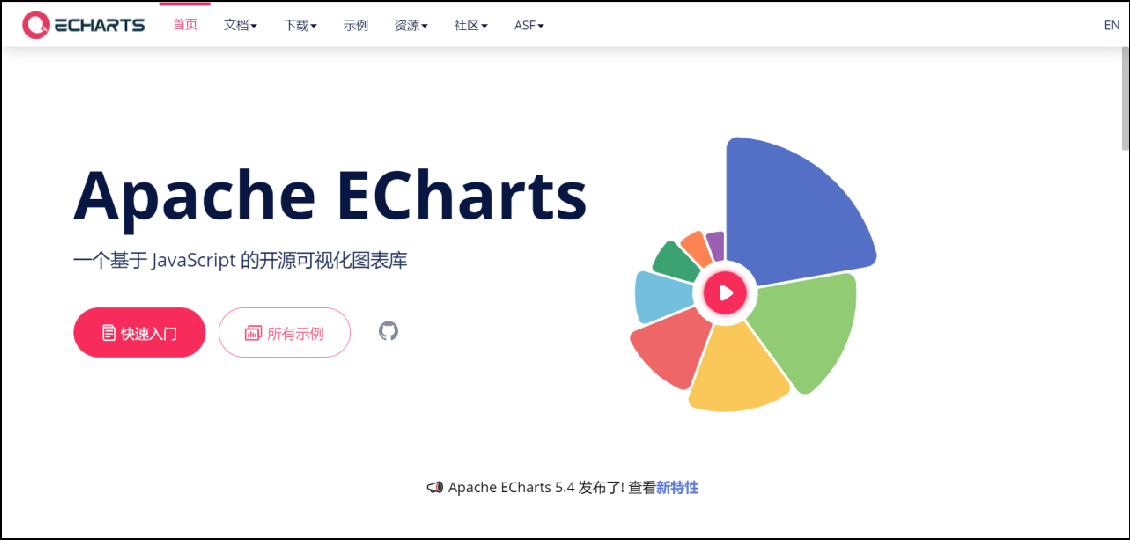 


**常见效果展示：**

1). 柱形图

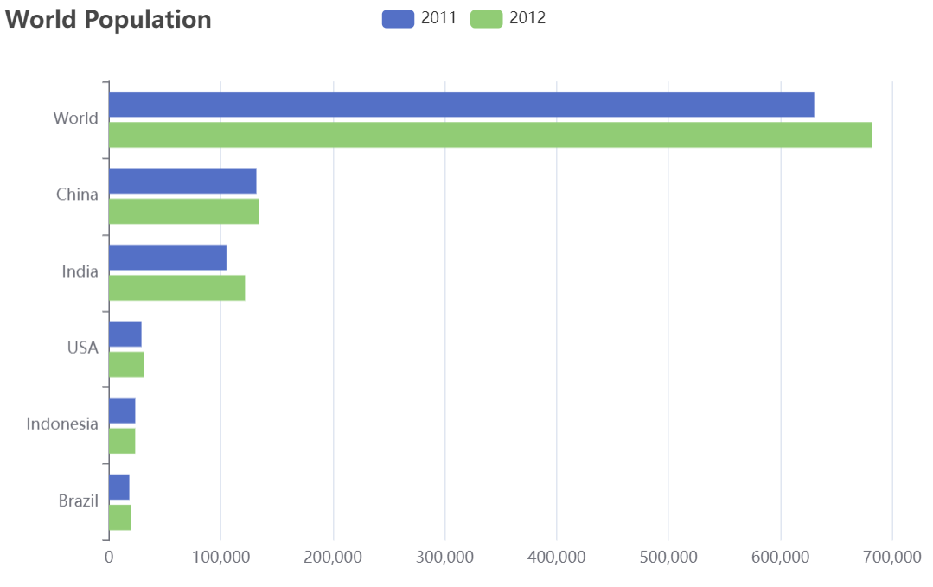 


2). 饼形图

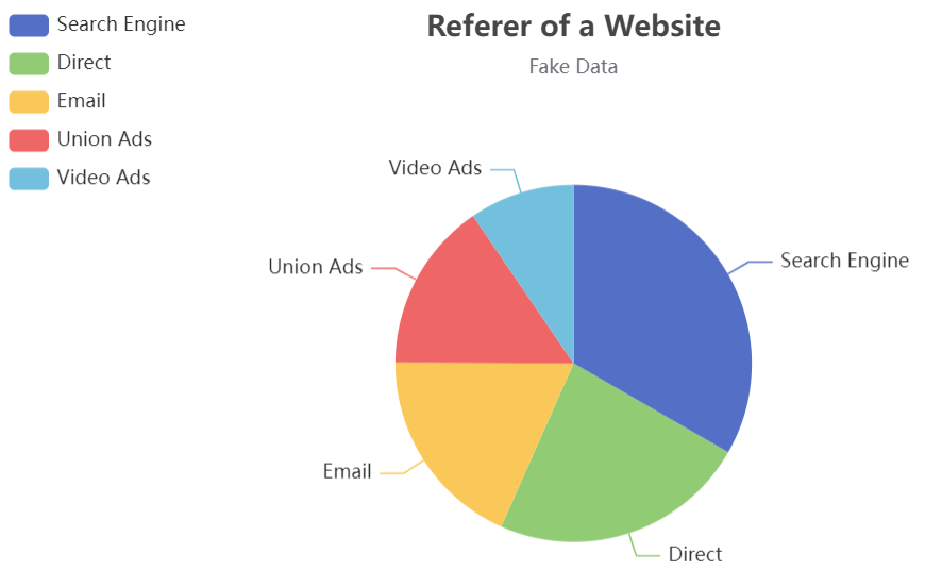 


3). 折线图

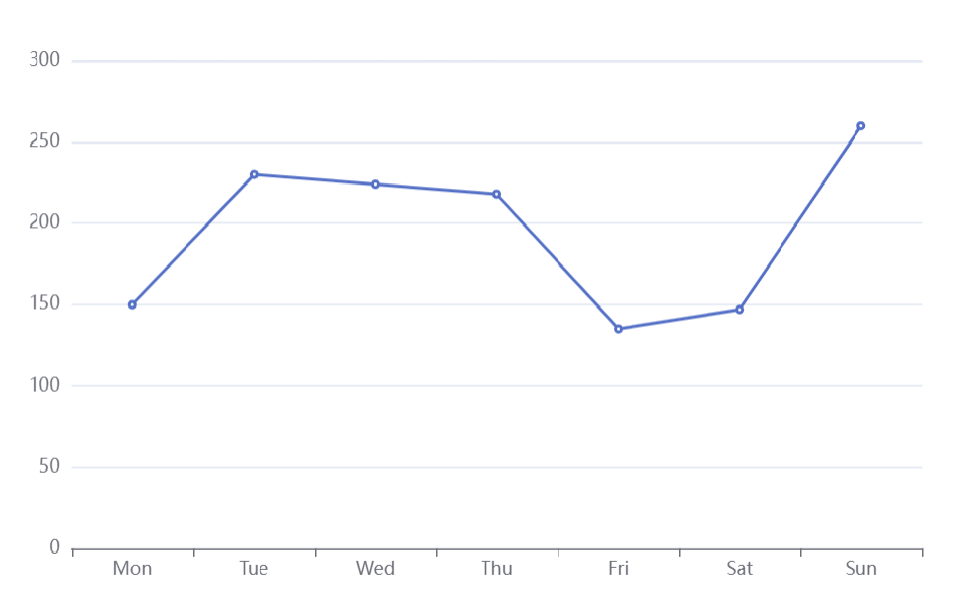 


**总结：**不管是哪种形式的图形，最本质的东西实际上是数据，它其实是对数据的一种可视化展示。


### 图表库与数据契约（补充）

ECharts负责把 option 中的数据渲染成图形，不负责定义业务统计口径。后端要先确定日期、数值、排序和空数据规则，前端再把它们映射到 `xAxis`、`series`、tooltip 和 legend。

管理端页面加载、窗口缩放或标签页切换时，要调用图表实例的 `resize`，切换日期范围时要更新 option 而不是重复初始化实例。销毁页面时调用 `dispose`，避免同一 DOM 重复初始化。


### 1.2 入门案例

> **PPT对照：** 第8—9页。

Apache Echarts官方提供的快速入门：https://echarts.apache.org/handbook/zh/get-started/

**效果展示：**

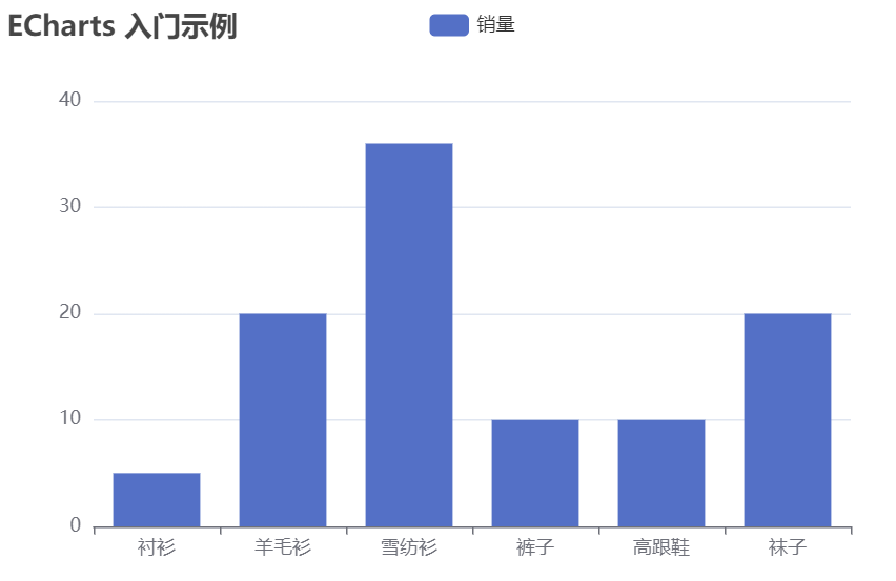 


**实现步骤：**

1). 引入echarts.js 文件(当天资料已提供)

2). 为 ECharts 准备一个设置宽高的 DOM

3). 初始化echarts实例

4). 指定图表的配置项和数据

5). 使用指定的配置项和数据显示图表


**代码开发：**

```html
<!DOCTYPE html>
<html>
  <head>
    <meta charset="utf-8" />
    <title>ECharts</title>
    <!-- 引入刚刚下载的 ECharts 文件 -->
    <script src="echarts.js"></script>
  </head>
  <body>
    <!-- 为 ECharts 准备一个定义了宽高的 DOM -->
    <div id="main" style="width: 600px;height:400px;"></div>
    <script type="text/javascript">
      // 基于准备好的dom，初始化echarts实例
      var myChart = echarts.init(document.getElementById('main'));

      // 指定图表的配置项和数据
      var option = {
        title: {
          text: 'ECharts 入门示例'
        },
        tooltip: {},
        legend: {
          data: ['销量']
        },
        xAxis: {
          data: ['衬衫', '羊毛衫', '雪纺衫', '裤子', '高跟鞋', '袜子']
        },
        yAxis: {},
        series: [
          {
            name: '销量',
            type: 'bar',
            data: [5, 20, 36, 10, 10, 20]
          }
        ]
      };

      // 使用刚指定的配置项和数据显示图表。
      myChart.setOption(option);
    </script>
  </body>
</html>
```


**测试：**(当天资料中已提供)

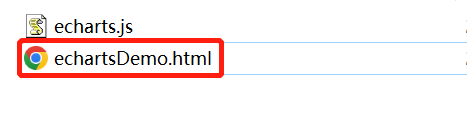 

使用浏览器方式打开即可。


**总结：**使用Echarts，重点在于研究当前图表所需的数据格式。通常是需要后端提供符合格式要求的动态数据，然后响应给前端来展示图表。


### ECharts 示例的工程注意事项（补充）

示例中的 `echarts.js` 路径只适合资料目录。项目中应通过前端依赖或固定静态资源路径加载，并在资源失败时给用户可理解的提示。图表数据应来自后端接口，不能把示例商品销量当成真实统计。

数值轴需要统一金额单位和小数位；日期轴要明确字符串格式与时区。后端返回的日期数组与每条 series 的 data 数组必须等长，空日补0。


## 2. 营业额统计

> **PPT对照：** 第10—23页。


### 2.1 需求分析和设计

> **PPT对照：** 第12—13页。

#### 2.1.1 产品原型

营业额统计是基于折现图来展现，并且按照天来展示的。实际上，就是某一个时间范围之内的每一天的营业额。同时，不管光标放在哪个点上，那么它就会把具体的数值展示出来。并且还需要注意日期并不是固定写死的，是由上边时间选择器来决定。比如选择是近7天、或者是近30日，或者是本周，就会把相应这个时间段之内的每一天日期通过横坐标展示。

**原型图：**

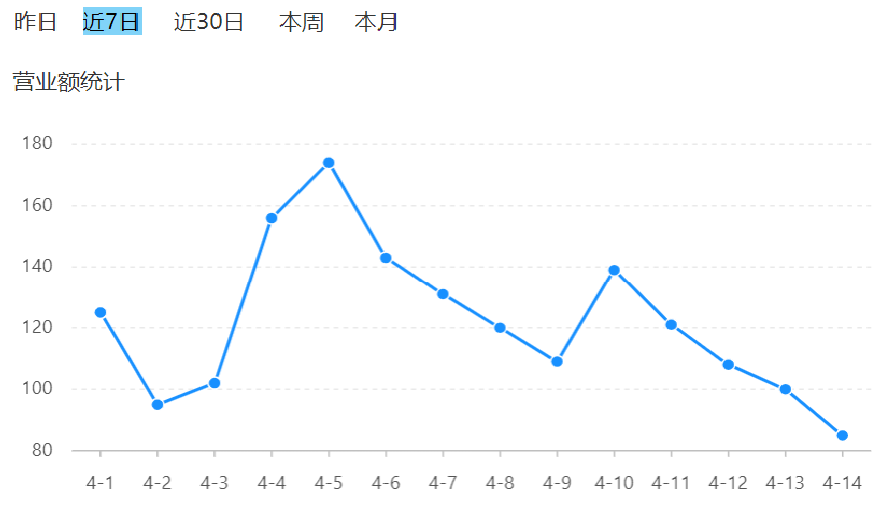 


**业务规则：**

- 营业额指订单状态为已完成的订单金额合计
- 基于可视化报表的折线图展示营业额数据，X轴为日期，Y轴为营业额
- 根据时间选择区间，展示每天的营业额数据


#### 2.1.2 接口设计

通过上述原型图，设计出对应的接口。


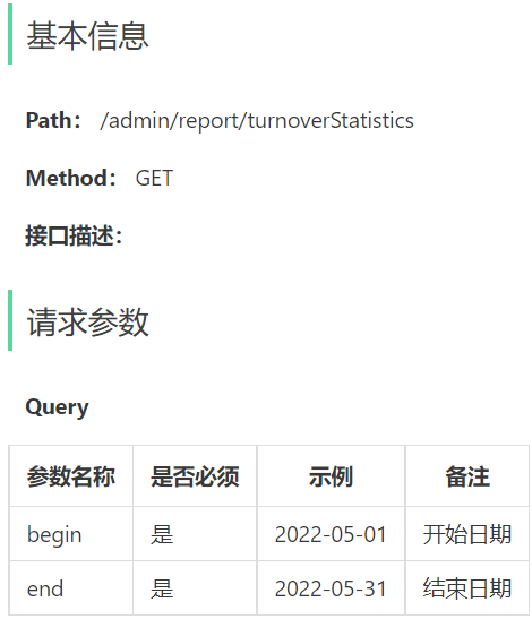 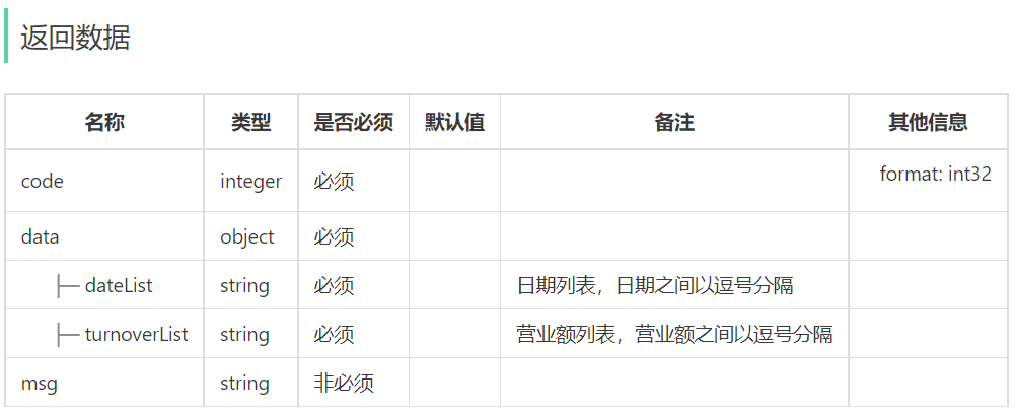 


**注意：**具体返回数据一般由前端来决定，前端展示图表，具体折现图对应数据是什么格式，是有固定的要求的。
所以说，后端需要去适应前端，它需要什么格式的数据，我们就给它返回什么格式的数据。


### 营业额统计口径与时间边界（补充）

营业额按已完成订单统计，退款、取消、待付款和待接单订单不应计入。是否扣除退款、优惠、配送费和打包费要由产品口径定义；不能因为数据库有 `amount` 就默认它等于财务口径营业额。

日期查询建议使用半开区间：整体范围为 `[begin 00:00, end+1天 00:00)`。这样不会依赖数据库能否精确保存 `23:59:59.999999999`，也避免相邻报表出现重复或遗漏。

接口应拒绝 begin 为空、end 为空、begin 晚于 end 和超长日期范围；应设置最大查询天数，避免一次请求触发大量聚合查询。


### 2.2 代码开发

> **PPT对照：** 第15—21页。

#### 2.2.1 VO设计

**根据接口定义设计对应的VO：**

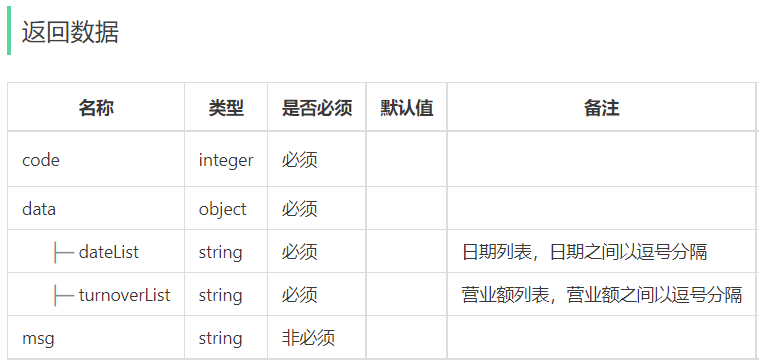 

在sky-pojo模块，TurnoverReportVO.java已定义

```java
package com.sky.vo;

import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;

import java.io.Serializable;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class TurnoverReportVO implements Serializable {

    //日期，以逗号分隔，例如：2022-10-01,2022-10-02,2022-10-03
    private String dateList;

    //营业额，以逗号分隔，例如：406.0,1520.0,75.0
    private String turnoverList;

}
```


#### 2.2.2 Controller层

**根据接口定义创建ReportController：**

```java
package com.sky.controller.admin;

import com.sky.result.Result;
import com.sky.service.ReportService;
import com.sky.vo.TurnoverReportVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.format.annotation.DateTimeFormat;
import org.springframework.web.bind.annotation.GetMapping;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import java.time.LocalDate;

/**
 * 报表
 */
@RestController
@RequestMapping("/admin/report")
@Slf4j
@Api(tags = "统计报表相关接口")
public class ReportController {

    @Autowired
    private ReportService reportService;

    /**
     * 营业额数据统计
     *
     * @param begin
     * @param end
     * @return
     */
    @GetMapping("/turnoverStatistics")
    @ApiOperation("营业额数据统计")
    public Result<TurnoverReportVO> turnoverStatistics(
            @DateTimeFormat(pattern = "yyyy-MM-dd")
                    LocalDate begin,
            @DateTimeFormat(pattern = "yyyy-MM-dd")
                    LocalDate end) {
        return Result.success(reportService.getTurnover(begin, end));
    }

}
```


#### 2.2.3 Service层接口

**创建ReportService接口，声明getTurnover方法：**

```java
package com.sky.service;

import com.sky.vo.TurnoverReportVO;
import java.time.LocalDate;

public interface ReportService {

    /**
     * 根据时间区间统计营业额
     * @param beginTime
     * @param endTime
     * @return
     */
    TurnoverReportVO getTurnover(LocalDate beginTime, LocalDate endTime);
}
```


#### 2.2.4 Service层实现类

**创建ReportServiceImpl实现类，实现getTurnover方法:**

```java
package com.sky.service.impl;

import com.sky.entity.Orders;
import com.sky.mapper.OrderMapper;
import com.sky.service.ReportService;
import com.sky.vo.TurnoverReportVO;
import lombok.extern.slf4j.Slf4j;
import org.apache.commons.lang.StringUtils;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;
import java.time.LocalDate;
import java.time.LocalDateTime;
import java.time.LocalTime;
import java.util.ArrayList;
import java.util.HashMap;
import java.util.List;
import java.util.Map;

@Service
@Slf4j
public class ReportServiceImpl implements ReportService {

    @Autowired
    private OrderMapper orderMapper;

    /**
     * 根据时间区间统计营业额
     * @param begin
     * @param end
     * @return
     */
    public TurnoverReportVO getTurnover(LocalDate begin, LocalDate end) {
        List<LocalDate> dateList = new ArrayList<>();
        dateList.add(begin);

        while (!begin.equals(end)){
            begin = begin.plusDays(1);//日期计算，获得指定日期后1天的日期
            dateList.add(begin);
        }
        
       List<Double> turnoverList = new ArrayList<>();
        for (LocalDate date : dateList) {
            LocalDateTime beginTime = LocalDateTime.of(date, LocalTime.MIN);
            LocalDateTime endTime = LocalDateTime.of(date, LocalTime.MAX);
            Map map = new HashMap();
        	map.put("status", Orders.COMPLETED);
        	map.put("begin",beginTime);
        	map.put("end", endTime);
            Double turnover = orderMapper.sumByMap(map); 
            turnover = turnover == null ? 0.0 : turnover;
            turnoverList.add(turnover);
        }

        //数据封装
        return TurnoverReportVO.builder()
                .dateList(StringUtils.join(dateList,","))
                .turnoverList(StringUtils.join(turnoverList,","))
                .build();
    }
}
```


#### 2.2.5 Mapper层

**在OrderMapper接口声明sumByMap方法：**

```java
	/**
     * 根据动态条件统计营业额
     * @param map
     */
    Double sumByMap(Map map);
```

**在OrderMapper.xml文件中编写动态SQL：**

```xml
<select id="sumByMap" resultType="java.lang.Double">
        select sum(amount) from orders
        <where>
            <if test="status != null">
                and status = #{status}
            </if>
            <if test="begin != null">
                and order_time &gt;= #{begin}
            </if>
            <if test="end != null">
                and order_time &lt;= #{end}
            </if>
        </where>
</select>
```


### 营业额实现的精度、性能与SQL（补充与勘误）

原实现每天循环一次 `sumByMap`，时间范围30天就发30次SQL；金额返回 `Double` 也可能出现二进制浮点误差。改进方向如下：

1. **金额类型。** 数据库 `decimal` 映射为 `BigDecimal`，前端按约定格式化；不要用 `Double` 做财务计算。
2. **一次聚合。** 让数据库按日期分组统计，服务层把结果映射到完整日期轴，缺失日期补零。范围很小且课程重点是流程时，原按天查询可以保留，但要认识到它是 N+1 查询。
3. **边界检查。** 使用 `[begin, endExclusive)`，并给 `order_time`、`status` 建合适索引。SQL 中明确 `o.order_time`，不要依赖单表字段名解析。
4. **返回契约。** `dateList` 与 `turnoverList` 顺序和长度必须一致，空结果不能返回 null 列表。

一次聚合的示意查询：

```sql
select date(order_time) as stat_date,
       coalesce(sum(amount), 0) as turnover
from orders
where status = 5
  and order_time >= #{begin}
  and order_time < #{endExclusive}
group by date(order_time)
order by stat_date
```

如果数据库按UTC保存时间，`date(order_time)` 前要按门店时区转换；不要把数据库时区问题留给前端猜测。`StringUtils.join` 是展示格式，不应掩盖数值精度和空值处理。


### 2.3 功能测试

> **PPT对照：** 第23页。

可以通过如下方式进行测试：

- 接口文档测试
- 前后端联调测试

启动服务器，启动nginx，直接采用前后端联调测试。

进入数据统计模块

**1). 查看近7日营业额统计**

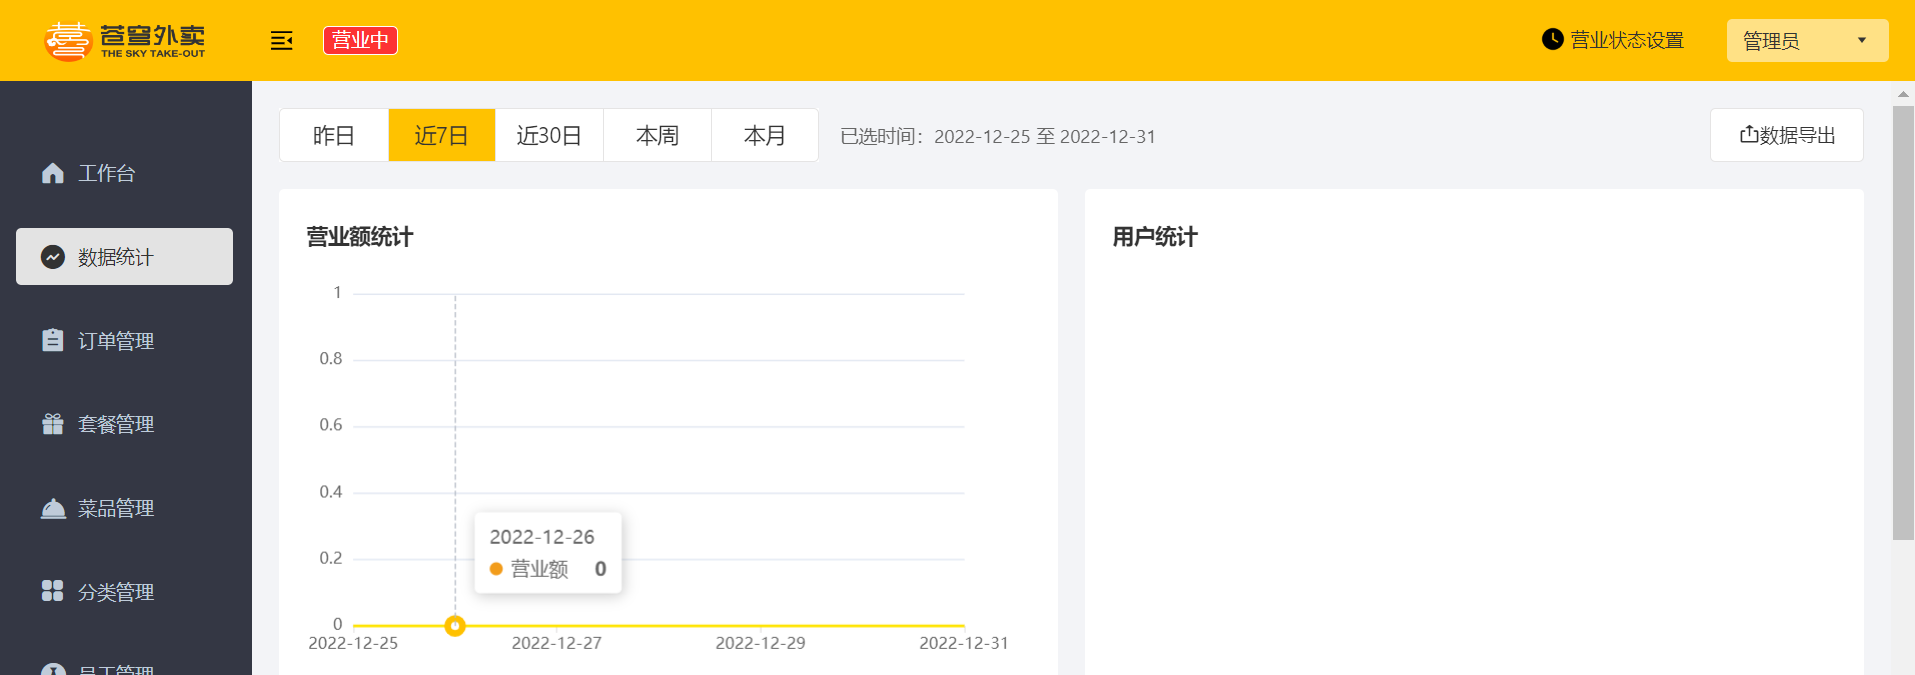 

进入开发者模式，查看返回数据

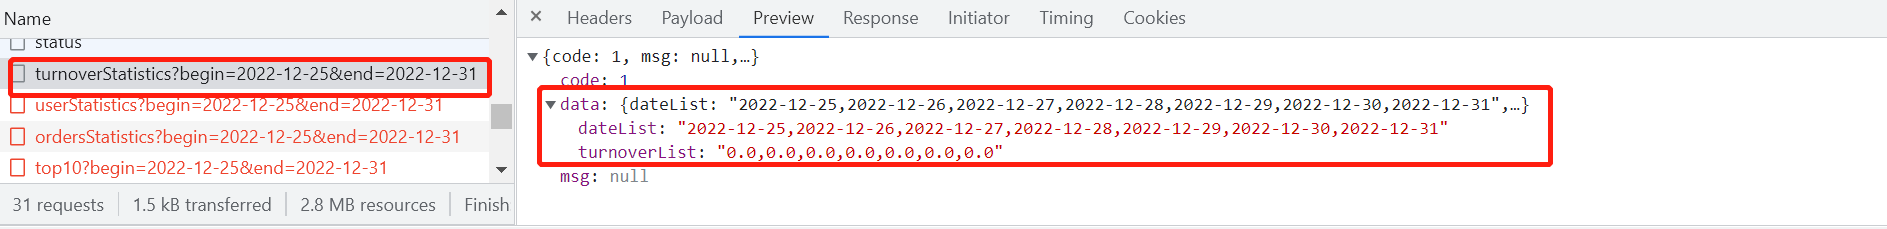 


**2). 查看近30日营业额统计**

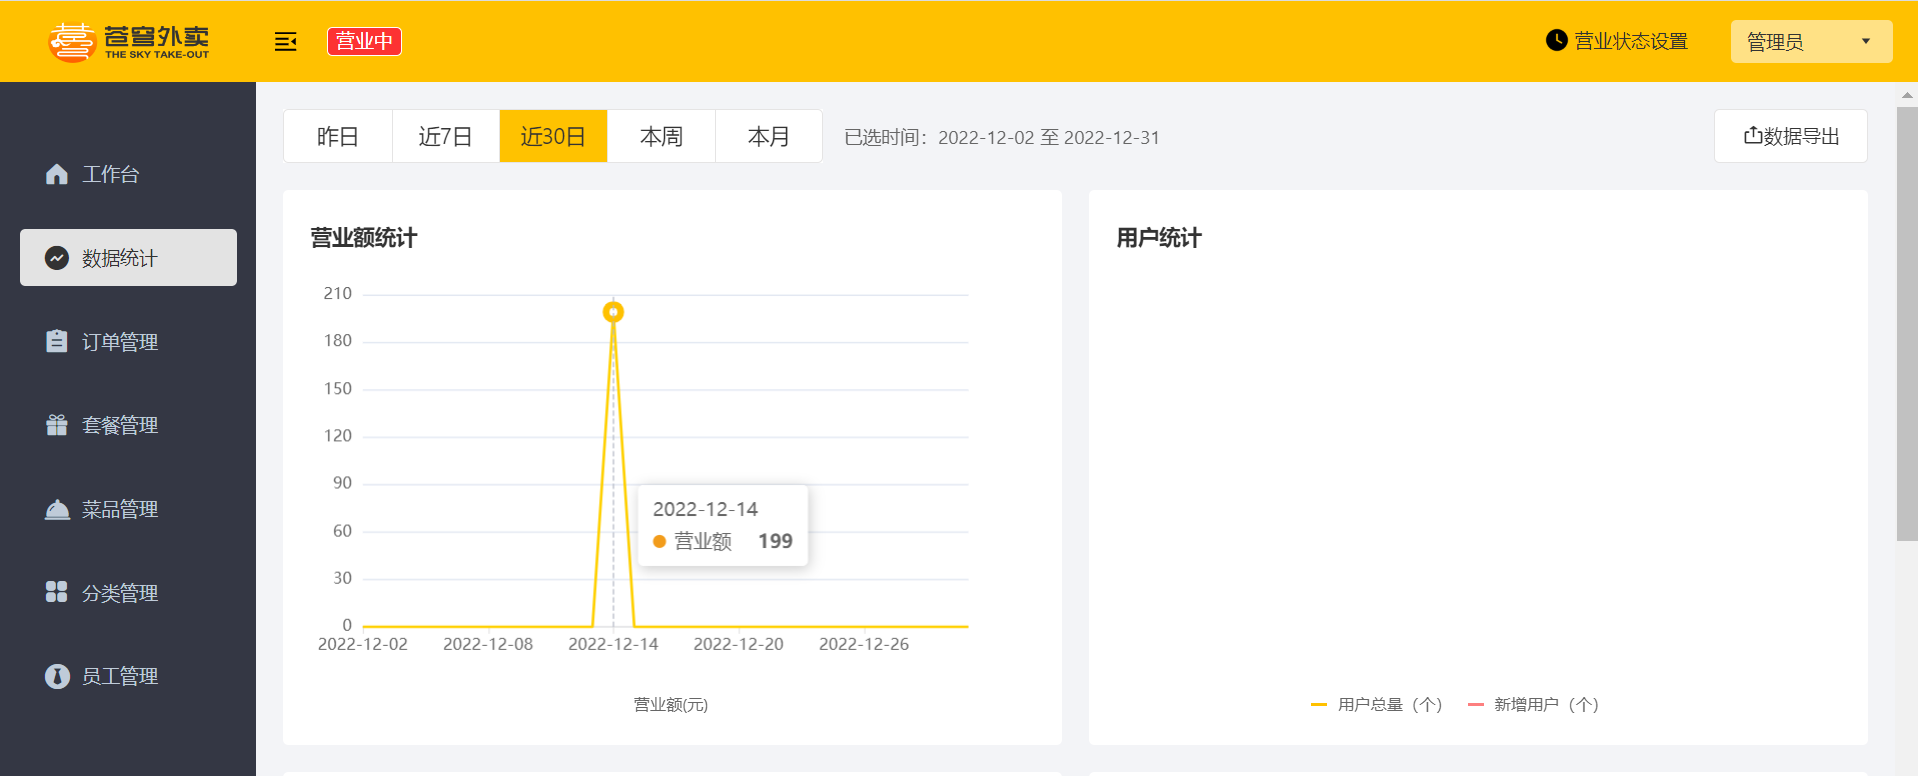 

进入开发者模式，查看返回数据

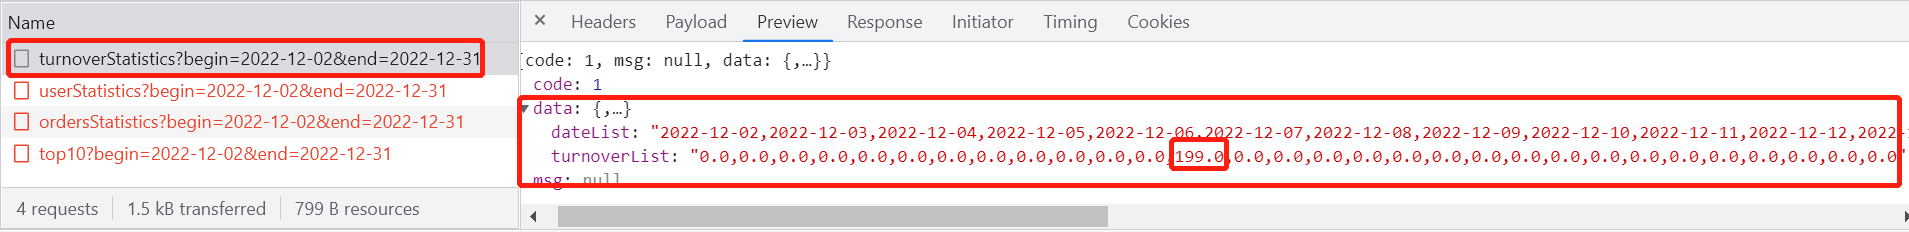 

也可通过断点方式启动，查看每步执行情况。


### 营业额验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 单日有已完成订单 | 金额等于业务口径的完成订单合计 |
| 有取消、待付款和待接单订单 | 不计入营业额 |
| 某些日期没有订单 | 日期保留，金额为0 |
| begin=end | 返回这一天一项数据 |
| begin>end、缺失参数 | 参数错误，不执行全表查询 |
| 退款或优惠订单 | 按明确财务口径处理 |
| 大范围查询 | 有最大范围限制，响应时间可控 |

同时核对接口返回数组长度、日期顺序、金额小数位和数据库聚合结果，不只看折线图是否出现。


### 2.4 代码提交

> **PPT对照：** 课程提交页。

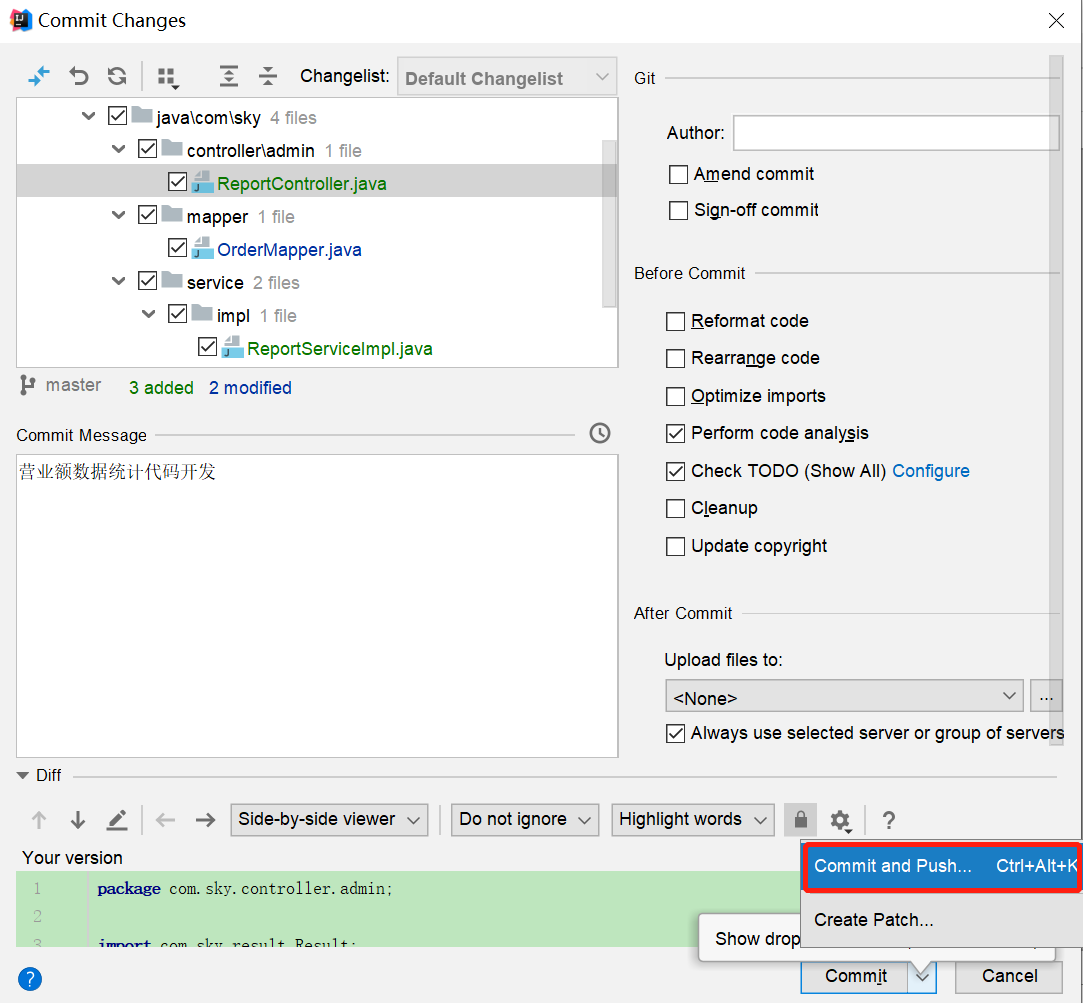 

后续步骤和其它功能代码提交一致，不再赘述。


### 营业额提交前检查（补充）

确认金额类型、日期边界、完成状态、空日期补零、范围校验和SQL索引已统一；不要把测试数据库中的示例金额写进接口默认值。


## 3. 用户统计

> **PPT对照：** 第24—38页。


### 3.1 需求分析和设计

> **PPT对照：** 第26—27页。

#### 3.1.1 产品原型

所谓用户统计，实际上统计的是用户的数量。通过折线图来展示，上面这根蓝色线代表的是用户总量，下边这根绿色线代表的是新增用户数量，是具体到每一天。所以说用户统计主要统计**两个数据**，一个是**总的用户数量**，另外一个是**新增用户数量**。

**原型图：**

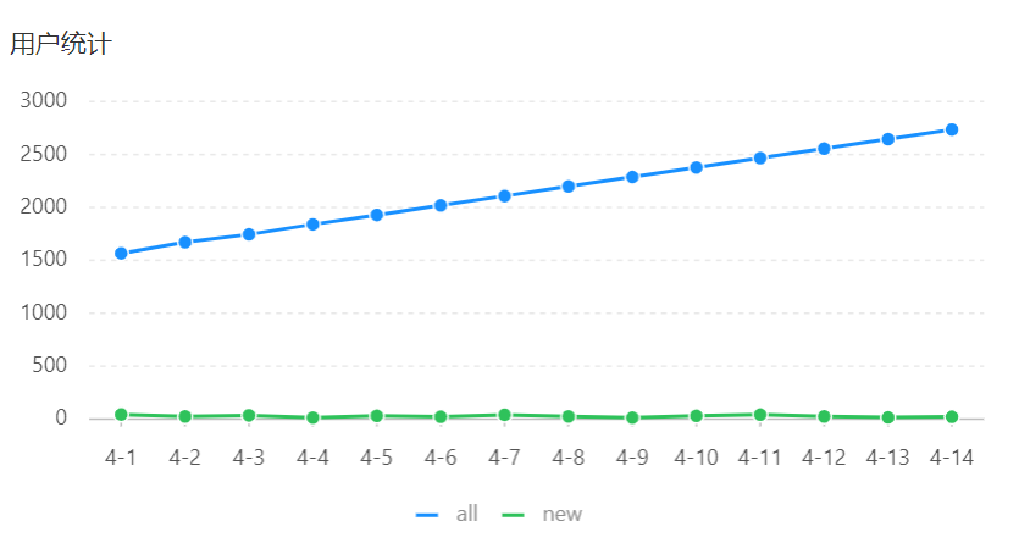 

**业务规则：**

- 基于可视化报表的折线图展示用户数据，X轴为日期，Y轴为用户数
- 根据时间选择区间，展示每天的用户总量和新增用户量数据


#### 3.1.2 接口设计

根据上述原型图设计接口。

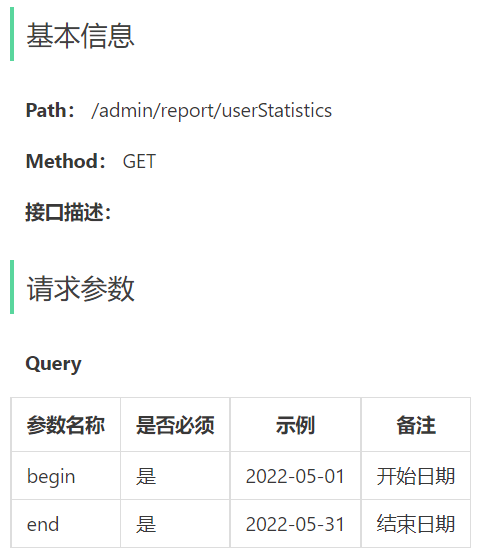 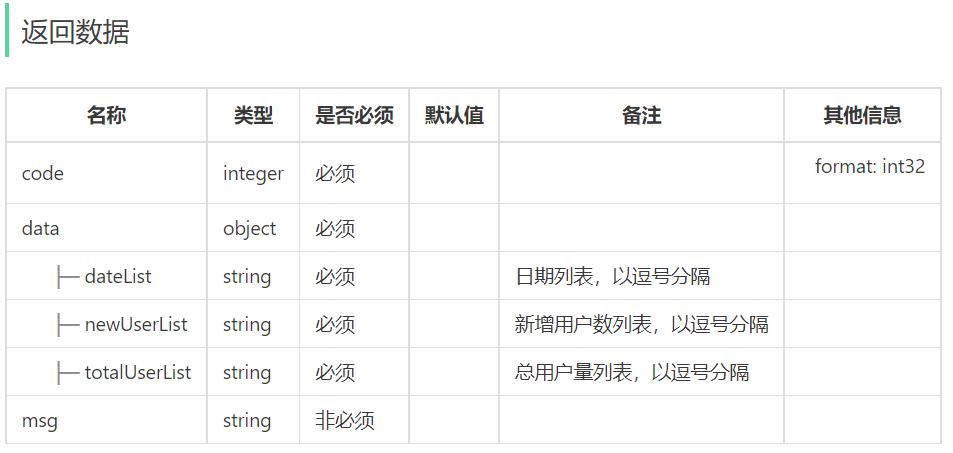


### 用户总量与新增量的定义（补充）

新增用户是当天创建的用户数；总用户量通常是截至当天结束已经创建的用户数。两者都按用户表 `create_time` 统计，与是否下过单无关。若产品要统计活跃用户，需要另定义登录、下单或去重规则。

总量曲线应单调不减；如果出现下降，优先检查时间边界、时区、软删除规则和数据迁移。匿名用户、管理员账号是否计入要由报表口径明确。


### 3.2 代码开发

> **PPT对照：** 第29—36页。

#### 3.2.1 VO设计

**根据用户统计接口的返回结果设计VO：**

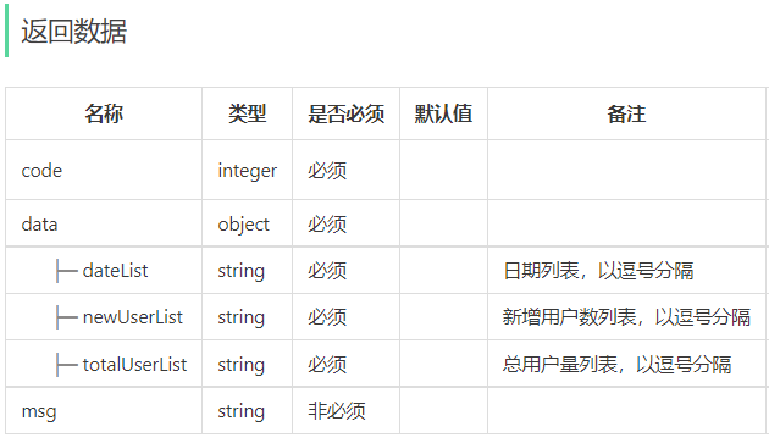 

在sky-pojo模块，UserReportVO.java已定义

```java
package com.sky.vo;

import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class UserReportVO implements Serializable {

    //日期，以逗号分隔，例如：2022-10-01,2022-10-02,2022-10-03
    private String dateList;

    //用户总量，以逗号分隔，例如：200,210,220
    private String totalUserList;

    //新增用户，以逗号分隔，例如：20,21,10
    private String newUserList;

}
```


#### 3.2.2 Controller层

**根据接口定义，在ReportController中创建userStatistics方法：**

```java
/**
     * 用户数据统计
     * @param begin
     * @param end
     * @return
     */
    @GetMapping("/userStatistics")
    @ApiOperation("用户数据统计")
    public Result<UserReportVO> userStatistics(
            @DateTimeFormat(pattern = "yyyy-MM-dd") LocalDate begin,
            @DateTimeFormat(pattern = "yyyy-MM-dd") LocalDate end){

        return Result.success(reportService.getUserStatistics(begin,end));            
}
```


#### 3.2.3 Service层接口

**在ReportService接口中声明getUserStatistics方法：**

```java
	/**
     * 根据时间区间统计用户数量
     * @param begin
     * @param end
     * @return
     */
    UserReportVO getUserStatistics(LocalDate begin, LocalDate end);
```


#### 3.2.4 Service层实现类

**在ReportServiceImpl实现类中实现getUserStatistics方法：**

```java
	@Override
    public UserReportVO getUserStatistics(LocalDate begin, LocalDate end) {
        List<LocalDate> dateList = new ArrayList<>();
        dateList.add(begin);

        while (!begin.equals(end)){
            begin = begin.plusDays(1);
            dateList.add(begin);
        }
        List<Integer> newUserList = new ArrayList<>(); //新增用户数
        List<Integer> totalUserList = new ArrayList<>(); //总用户数

        for (LocalDate date : dateList) {
            LocalDateTime beginTime = LocalDateTime.of(date, LocalTime.MIN);
            LocalDateTime endTime = LocalDateTime.of(date, LocalTime.MAX);
            //新增用户数量 select count(id) from user where create_time > ? and create_time < ?
            Integer newUser = getUserCount(beginTime, endTime);
            //总用户数量 select count(id) from user where  create_time < ?
            Integer totalUser = getUserCount(null, endTime);

            newUserList.add(newUser);
            totalUserList.add(totalUser);
        }

        return UserReportVO.builder()
                .dateList(StringUtils.join(dateList,","))
                .newUserList(StringUtils.join(newUserList,","))
                .totalUserList(StringUtils.join(totalUserList,","))
                .build();
    }
```

**在ReportServiceImpl实现类中创建私有方法getUserCount：**

```java
	/**
     * 根据时间区间统计用户数量
     * @param beginTime
     * @param endTime
     * @return
     */
    private Integer getUserCount(LocalDateTime beginTime, LocalDateTime endTime) {
        Map map = new HashMap();
        map.put("begin",beginTime);
        map.put("end", endTime);
        return userMapper.countByMap(map);
    }
```


#### 3.2.5 Mapper层

**在UserMapper接口中声明countByMap方法：**

```java
	/**
     * 根据动态条件统计用户数量
     * @param map
     * @return
     */
    Integer countByMap(Map map);
```

**在UserMapper.xml文件中编写动态SQL：**

```java
<select id="countByMap" resultType="java.lang.Integer">
        select count(id) from user
        <where>
            <if test="begin != null">
                and create_time &gt;= #{begin}
            </if>
            <if test="end != null">
                and create_time &lt;= #{end}
            </if>
        </where>
</select>
```


### 用户统计的边界、性能与空值（补充与勘误）

原实现每天查询两次用户表，仍有 N+1 查询；`getUserCount(null, endTime)` 的总量含义需要明确为“创建时间不晚于该日结束”。建议一次按日期聚合新增量，再用窗口累加得到总量，或在服务层对有索引的结果做累计。

原 `Integer` 适合课程数据量，真实用户数可能超出范围，数据库 `count` 可映射为 `Long`。`Map` 和原始集合应改为带泛型的参数对象，减少字段拼写错误。

日期范围验证必须在所有四个统计接口复用。SQL 半开区间示意：

```sql
select date(create_time) as stat_date, count(*) as new_count
from user
where create_time >= #{begin}
  and create_time < #{endExclusive}
group by date(create_time)
order by stat_date
```

服务层按完整日期轴补零，再用 `runningTotal += new_count` 生成总量。若存在历史删除或账号合并，累计新增不再等于当前表的简单 count，应改用业务定义的快照查询。


### 3.3 功能测试

> **PPT对照：** 第38页。

可以通过如下方式进行测试：

- 接口文档测试
- 前后端联调测试

进入数据统计模块

**1). 查看近7日用户统计**

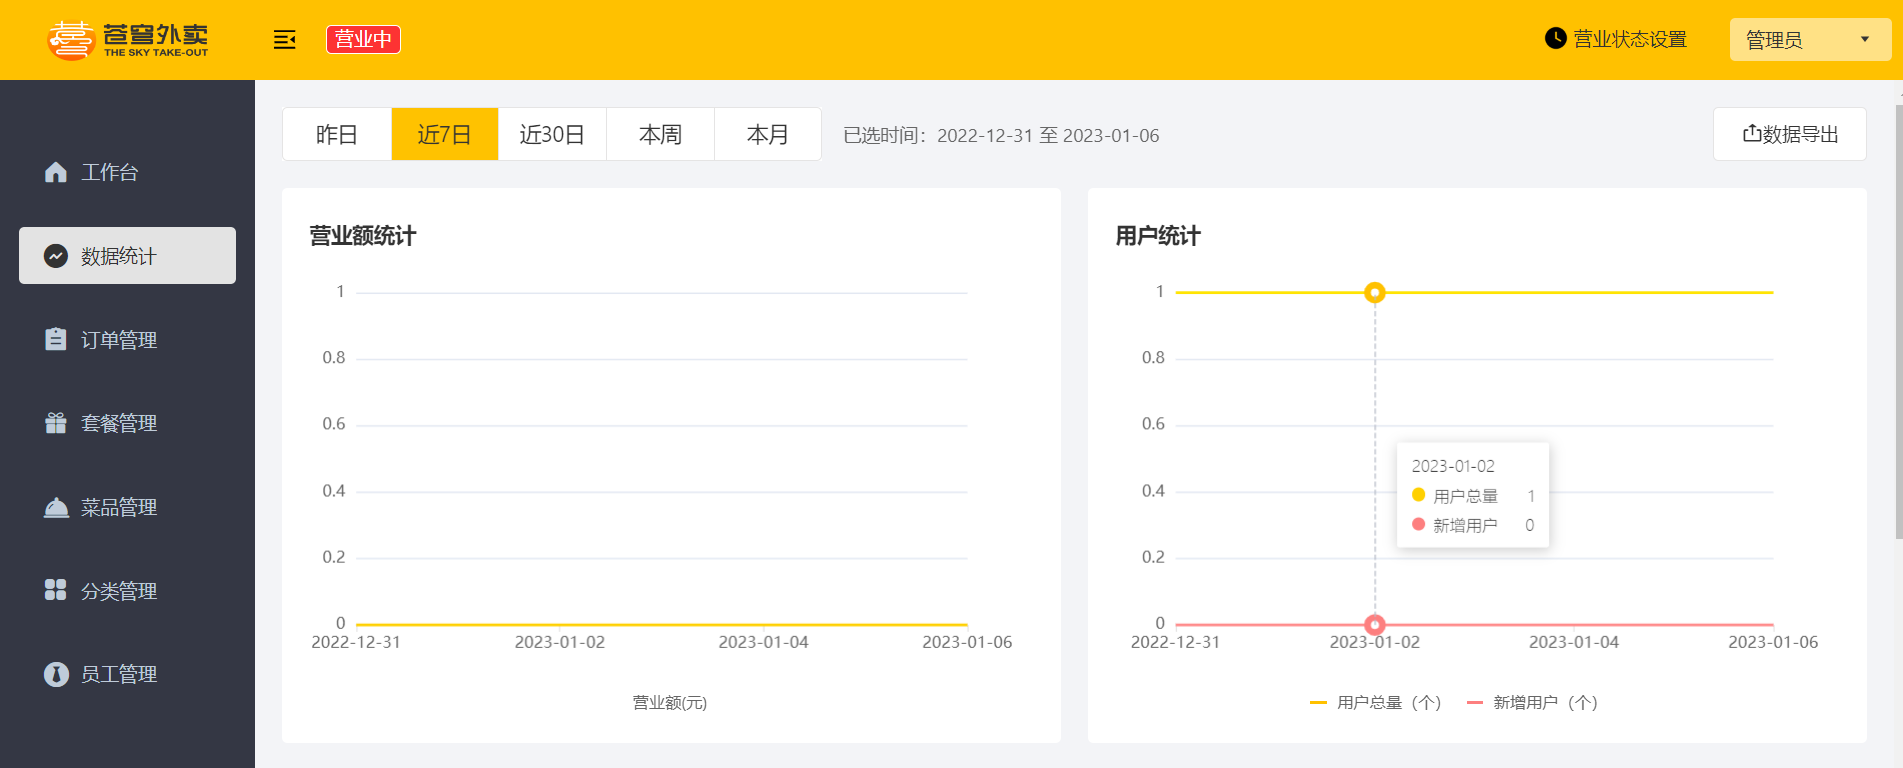 

进入开发者模式，查看返回数据

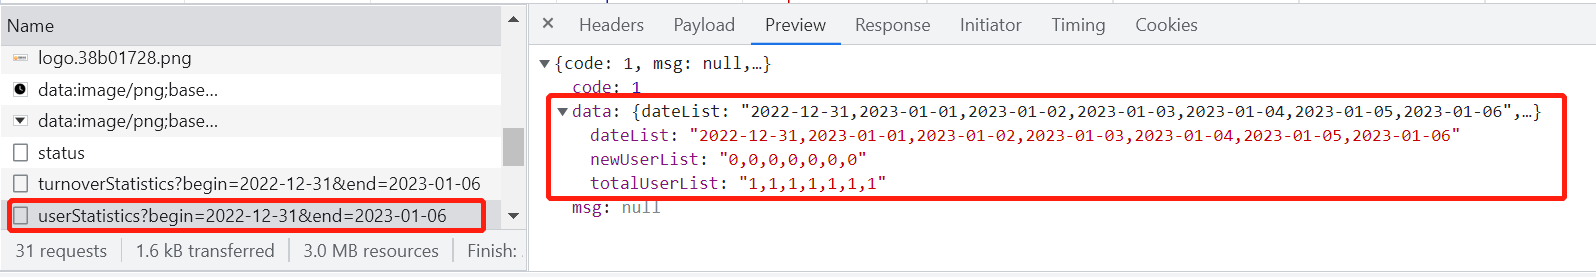 


**2). 查看近30日用户统计**

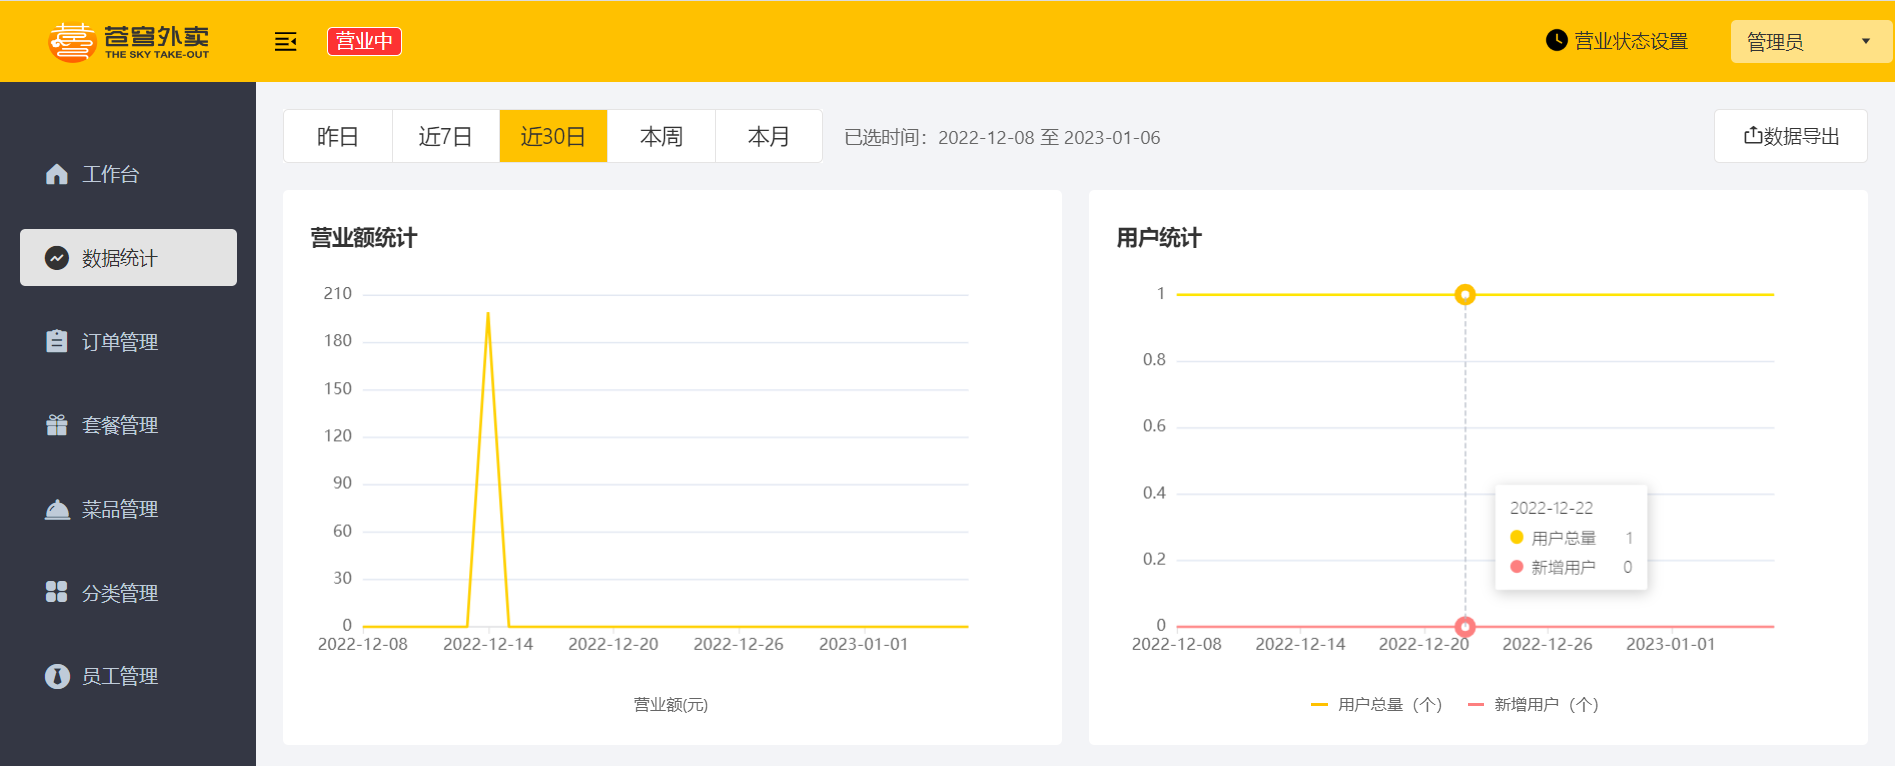 

进入开发者模式，查看返回数据

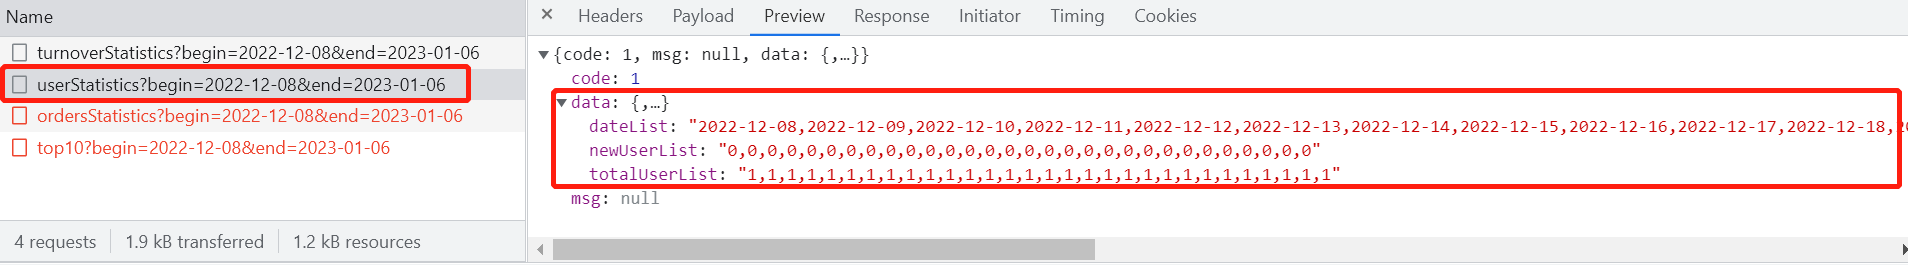 

也可通过断点方式启动，查看每步执行情况。


### 用户统计验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 某日新增用户 | newUserList 对应日期计数正确 |
| 无新增日期 | 新增为0，总量沿用前一天 |
| 查询首日之前已有用户 | 首日总量包含历史用户 |
| 管理员、匿名用户 | 按报表口径稳定处理 |
| 跨时区日期边界 | 按门店时区，不因服务器时区漂移 |
| 大量用户 | 查询有索引，数值不溢出 |

检查总量曲线、数组长度、日期轴和数据库样本；前端折线出现并不代表新增与总量口径正确。


### 3.4 代码提交

> **PPT对照：** 课程提交页。

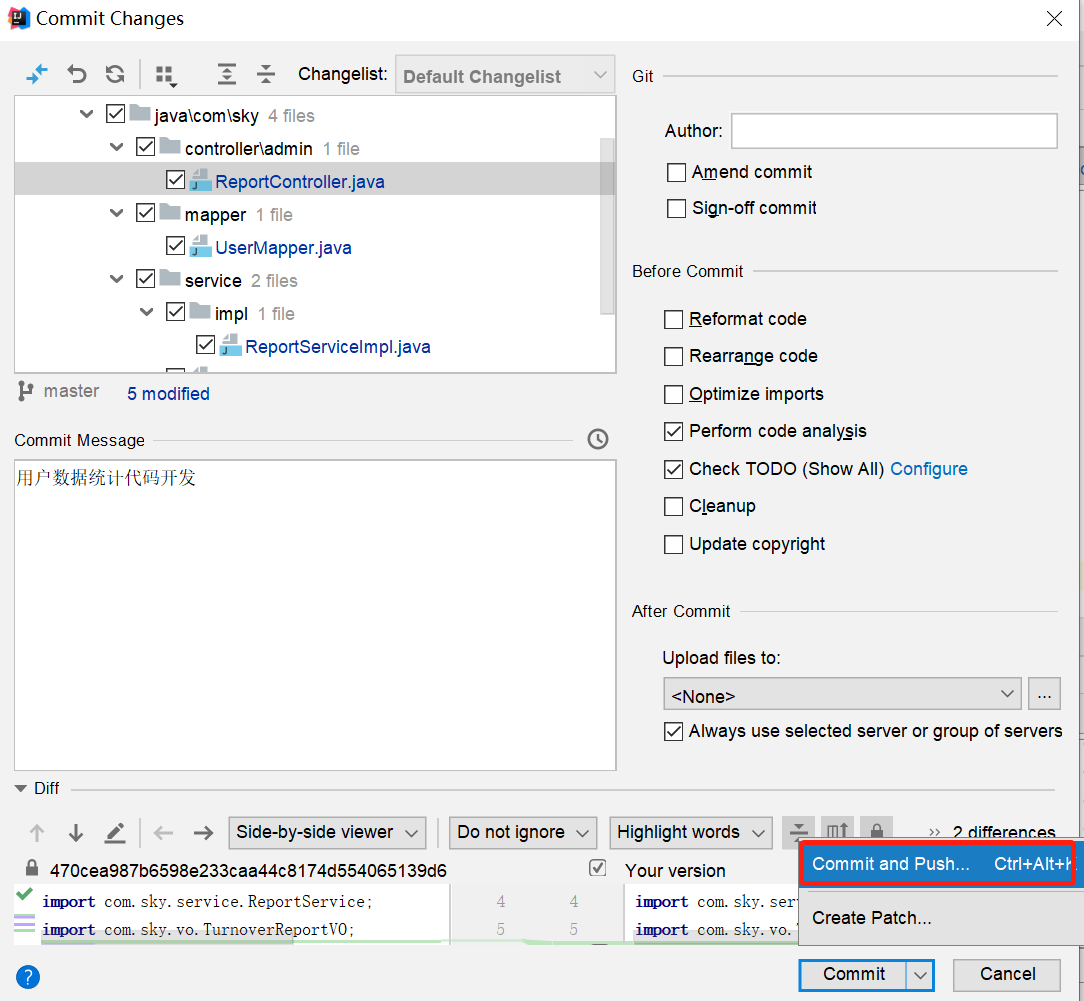 

后续步骤和其它功能代码提交一致，不再赘述。


### 用户统计提交前检查（补充）

确认新增、总量、管理员范围、时区、Long计数和空日期补零规则已写入接口说明，并与前端 series 名称对应。


## 4. 订单统计

> **PPT对照：** 第39—54页。


### 4.1 需求分析和设计

> **PPT对照：** 第41—42页。

#### 4.1.1 产品原型

订单统计通过一个折现图来展现，折线图上有两根线，这根蓝色的线代表的是订单总数，而下边这根绿色的线代表的是有效订单数，指的就是状态是已完成的订单就属于有效订单，分别反映的是每一天的数据。上面还有3个数字，分别是订单总数、有效订单、订单完成率，它指的是整个时间区间之内总的数据。

**原型图：**

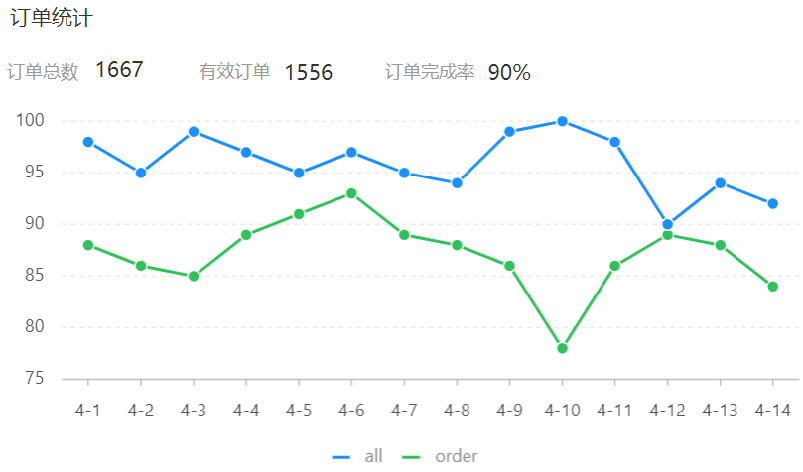 

**业务规则：**

- 有效订单指状态为 “已完成” 的订单
- 基于可视化报表的折线图展示订单数据，X轴为日期，Y轴为订单数量
- 根据时间选择区间，展示每天的订单总数和有效订单数
- 展示所选时间区间内的有效订单数、总订单数、订单完成率，订单完成率 = 有效订单数 / 总订单数 * 100%


#### 4.1.2 接口设计

根据上述原型图设计接口。

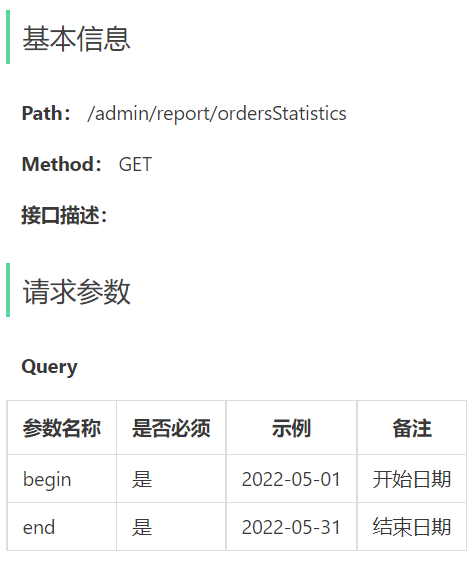 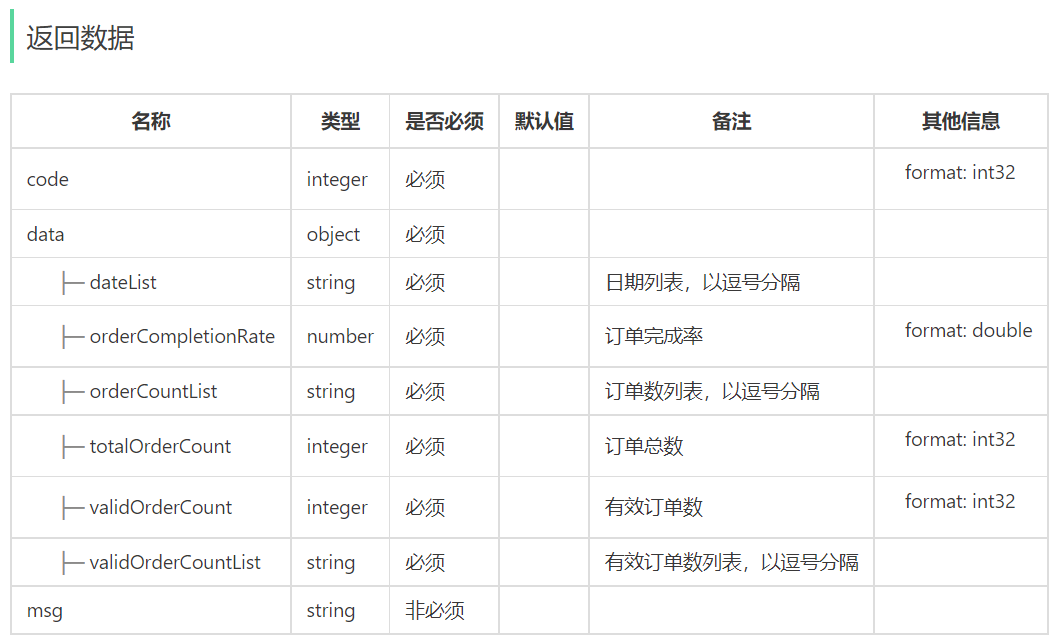


### 订单统计口径（补充）

订单总数统计时间范围内创建的所有订单；有效订单按已完成状态统计。订单完成率是区间内 `有效订单数 / 总订单数`，分母为0时应返回0并由前端显示为0%或“暂无数据”。

要明确统计的是下单日还是完成日。讲义按 `order_time` 统计，意味着某天创建、之后完成的订单会计入创建日的有效订单；如果产品需要按完成日统计，应使用 `checkout_time` 或完成时间字段，不能只改文案。


### 4.2 代码开发

> **PPT对照：** 第44—52页。

#### 4.2.1 VO设计

**根据订单统计接口的返回结果设计VO：**

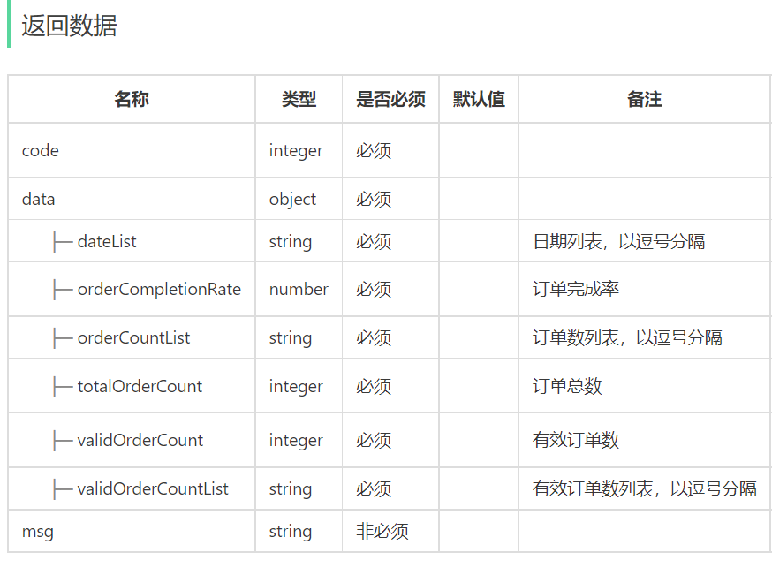 

在sky-pojo模块，OrderReportVO.java已定义

```java
package com.sky.vo;

import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class OrderReportVO implements Serializable {

    //日期，以逗号分隔，例如：2022-10-01,2022-10-02,2022-10-03
    private String dateList;

    //每日订单数，以逗号分隔，例如：260,210,215
    private String orderCountList;

    //每日有效订单数，以逗号分隔，例如：20,21,10
    private String validOrderCountList;

    //订单总数
    private Integer totalOrderCount;

    //有效订单数
    private Integer validOrderCount;

    //订单完成率
    private Double orderCompletionRate;

}
```


#### 4.2.2 Controller层

**在ReportController中根据订单统计接口创建orderStatistics方法：**

```java
/**
     * 订单数据统计
     * @param begin
     * @param end
     * @return
     */
    @GetMapping("/ordersStatistics")
    @ApiOperation("用户数据统计")
    public Result<OrderReportVO> orderStatistics(
            @DateTimeFormat(pattern = "yyyy-MM-dd")
                    LocalDate begin,
            @DateTimeFormat(pattern = "yyyy-MM-dd")
                    LocalDate end){

        return Result.success(reportService.getOrderStatistics(begin,end));
    }
```


#### 4.2.3 Service层接口

**在ReportService接口中声明getOrderStatistics方法：**

```java
/**
* 根据时间区间统计订单数量
* @param begin 
* @param end
* @return 
*/
OrderReportVO getOrderStatistics(LocalDate begin, LocalDate end);
```


#### 4.2.4 Service层实现类

**在ReportServiceImpl实现类中实现getOrderStatistics方法：**

```java
/**
* 根据时间区间统计订单数量
* @param begin 
* @param end
* @return 
*/
public OrderReportVO getOrderStatistics(LocalDate begin, LocalDate end){
	List<LocalDate> dateList = new ArrayList<>();
    dateList.add(begin);

    while (!begin.equals(end)){
          begin = begin.plusDays(1);
          dateList.add(begin);
     }
    //每天订单总数集合
     List<Integer> orderCountList = new ArrayList<>();
    //每天有效订单数集合
    List<Integer> validOrderCountList = new ArrayList<>();
    for (LocalDate date : dateList) {
         LocalDateTime beginTime = LocalDateTime.of(date, LocalTime.MIN);
         LocalDateTime endTime = LocalDateTime.of(date, LocalTime.MAX);
   //查询每天的总订单数 select count(id) from orders where order_time > ? and order_time < ?
         Integer orderCount = getOrderCount(beginTime, endTime, null);

  //查询每天的有效订单数 select count(id) from orders where order_time > ? and order_time < ? and status = ?
         Integer validOrderCount = getOrderCount(beginTime, endTime, Orders.COMPLETED);

         orderCountList.add(orderCount);
         validOrderCountList.add(validOrderCount);
        }

    //时间区间内的总订单数
    Integer totalOrderCount = orderCountList.stream().reduce(Integer::sum).get();
    //时间区间内的总有效订单数
    Integer validOrderCount = validOrderCountList.stream().reduce(Integer::sum).get();
    //订单完成率
    Double orderCompletionRate = 0.0;
    if(totalOrderCount != 0){
         orderCompletionRate = validOrderCount.doubleValue() / totalOrderCount;
     }
    return OrderReportVO.builder()
                .dateList(StringUtils.join(dateList, ","))
                .orderCountList(StringUtils.join(orderCountList, ","))
                .validOrderCountList(StringUtils.join(validOrderCountList, ","))
                .totalOrderCount(totalOrderCount)
                .validOrderCount(validOrderCount)
                .orderCompletionRate(orderCompletionRate)
                .build();
    
}
```

**在ReportServiceImpl实现类中提供私有方法getOrderCount：**

```java
/**
* 根据时间区间统计指定状态的订单数量
* @param beginTime
* @param endTime
* @param status
* @return
*/
private Integer getOrderCount(LocalDateTime beginTime, LocalDateTime endTime, Integer status) {
	Map map = new HashMap();
	map.put("status", status);
	map.put("begin",beginTime);
	map.put("end", endTime);
	return orderMapper.countByMap(map);
}
```


#### 4.2.5 Mapper层

**在OrderMapper接口中声明countByMap方法：**

```java
/**
*根据动态条件统计订单数量
* @param map
*/
Integer countByMap(Map map);
```

**在OrderMapper.xml文件中编写动态SQL：**

```java
<select id="countByMap" resultType="java.lang.Integer">
        select count(id) from orders
        <where>
            <if test="status != null">
                and status = #{status}
            </if>
            <if test="begin != null">
                and order_time &gt;= #{begin}
            </if>
            <if test="end != null">
                and order_time &lt;= #{end}
            </if>
        </where>
</select>
```


### 订单统计实现的精度与查询优化（补充与勘误）

原代码每天分别查询总订单和有效订单，再用 `stream().reduce(...).get()` 汇总。日期范围为空时 `get()` 可能没有值；接口还没有验证 begin/end。建议：

- 复用统一的日期范围校验和半开区间；
- 用一次按日期、状态分组的查询返回总数与有效数，避免每天多次SQL；
- 使用 `Long` 计数，完成率在服务层用 `BigDecimal` 或明确的 `double` 比例计算；
- 返回0到1的比例还是0到100的百分比必须写进接口契约，前端格式化不能靠猜。

示意SQL：

```sql
select date(order_time) as stat_date,
       count(*) as total_count,
       sum(case when status = 5 then 1 else 0 end) as valid_count
from orders
where order_time >= #{begin}
  and order_time < #{endExclusive}
group by date(order_time)
order by stat_date
```

`sum(case...)` 为空时要用 `coalesce` 或服务层补0。状态常量要与订单实体一致，不要在报表SQL里散落难以维护的数字。


### 4.3 功能测试

> **PPT对照：** 第54页。

可以通过如下方式进行测试：

- 接口文档测试
- 前后端联调

重启服务，直接采用前后端联调测试。

进入数据统计模块

**1). 查看近7日订单统计**

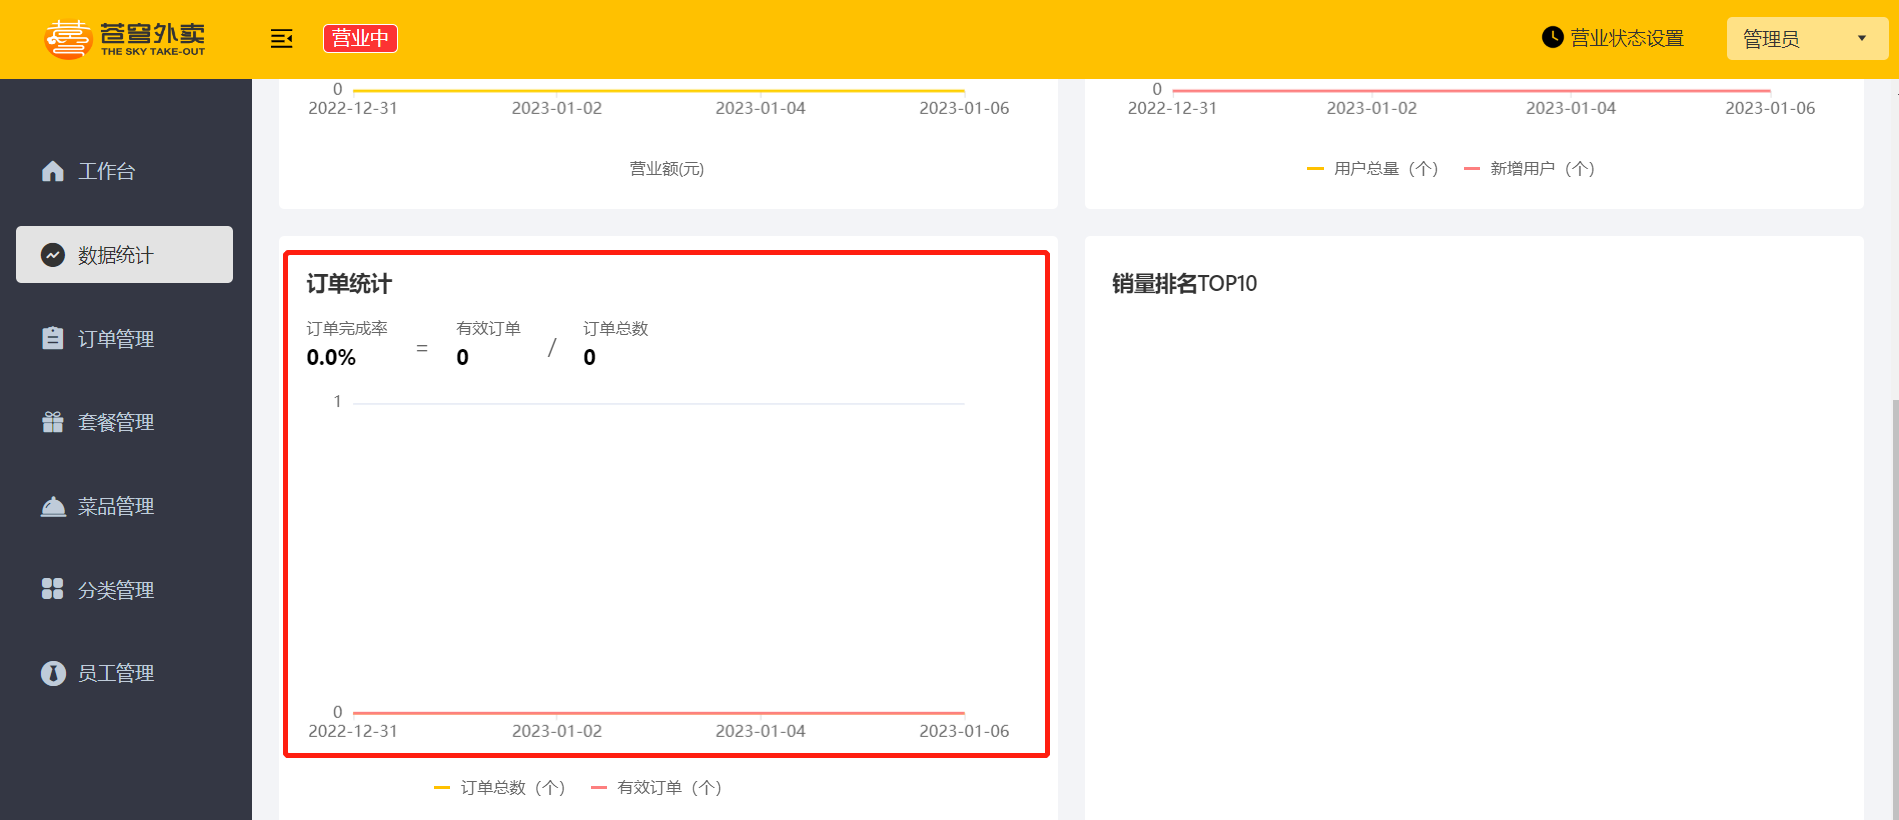 

进入开发者模式，查看返回数据

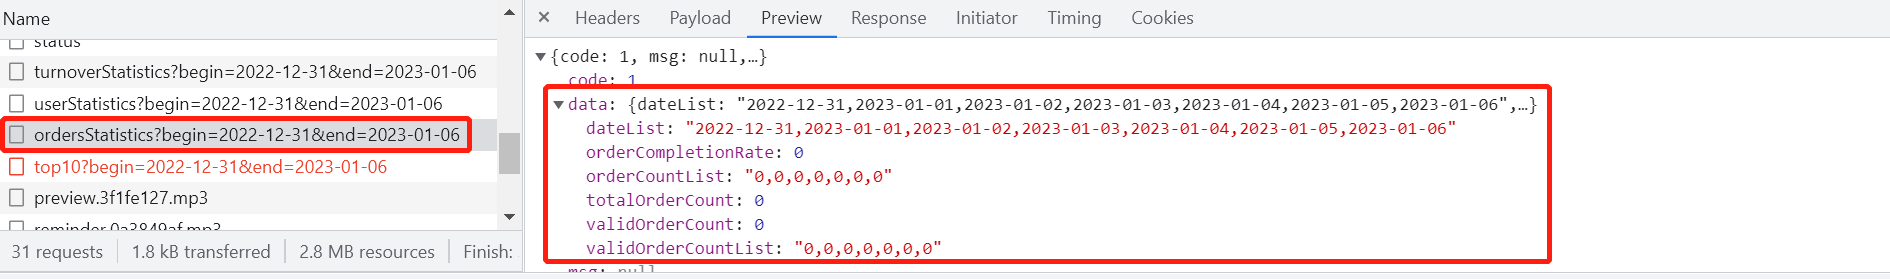 


**2). 查看近30日订单统计**

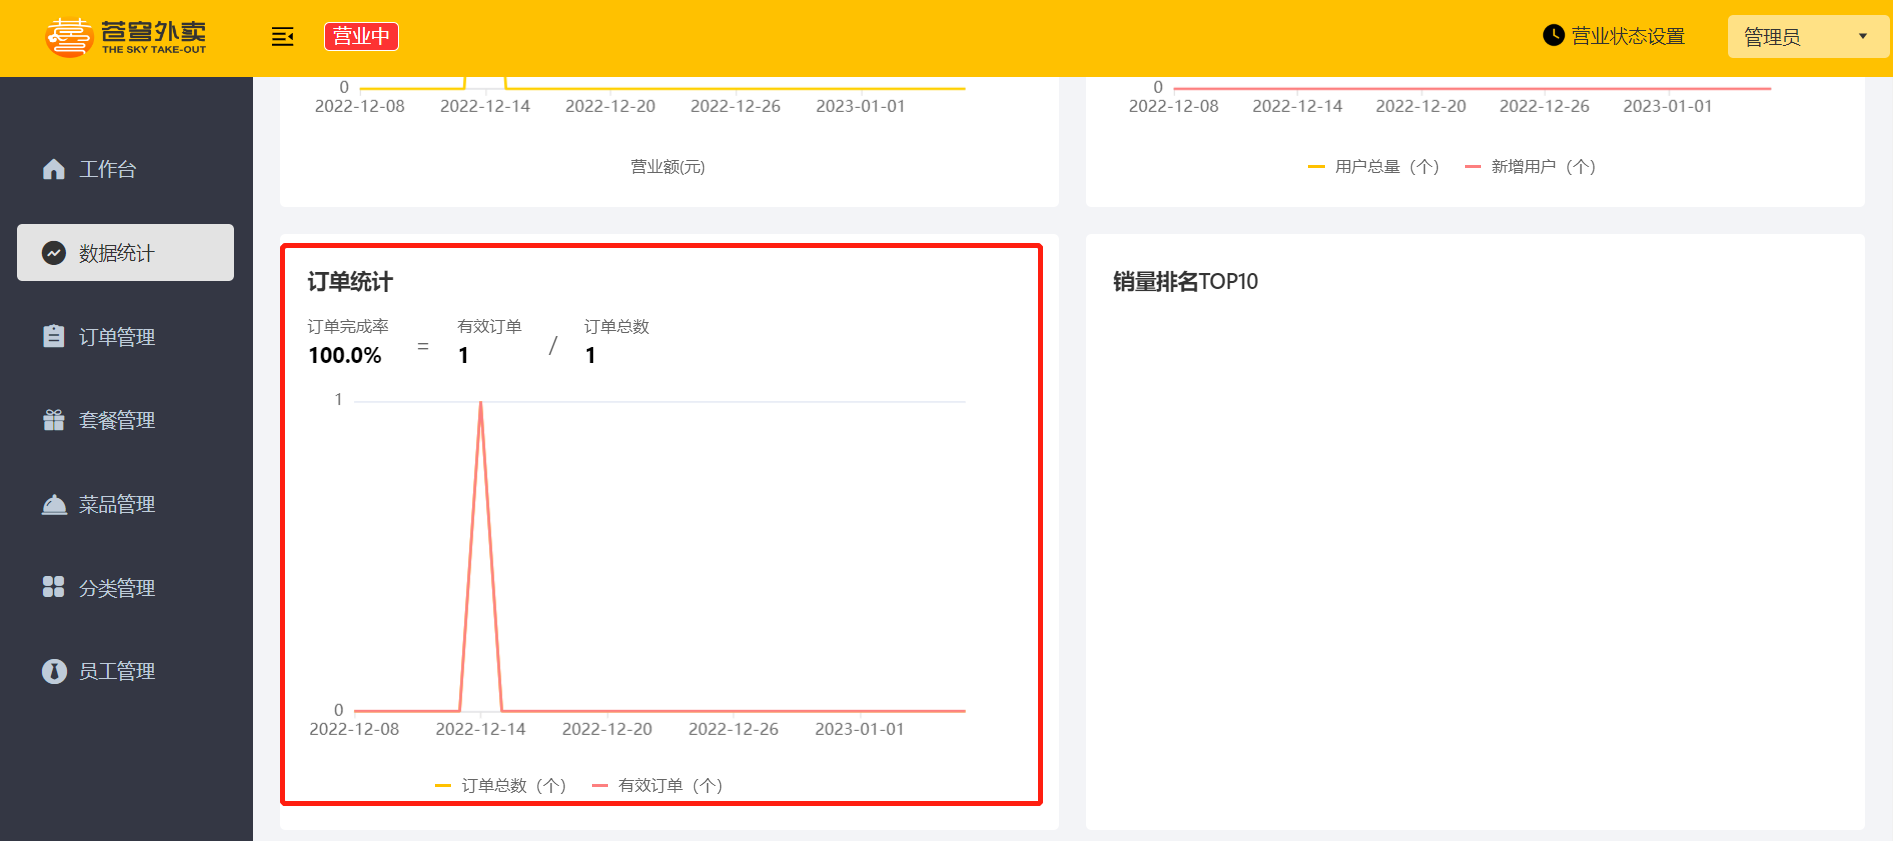 

进入开发者模式，查看返回数据

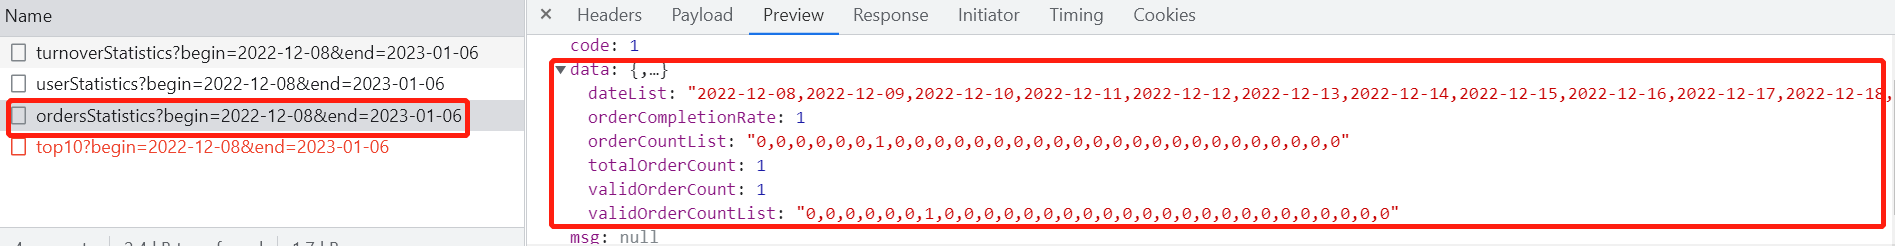 

也可通过断点方式启动，查看每步执行情况。


### 订单统计验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 有总订单和已完成订单 | 每日两条曲线与区间汇总一致 |
| 全部未完成 | 有效数为0，完成率为0 |
| 没有订单 | 日期轴完整，汇总为0，不抛异常 |
| 跨日边界订单 | 只计入定义的下单日或完成日 |
| 取消、退款订单 | 按有效订单口径处理 |
| 分母为0 | 不出现 NaN 或 Infinity |
| 大范围查询 | 统计性能和计数类型可接受 |

核对完成率原始值、前端百分号显示和区间总数，不要只看图形趋势。


### 4.4 代码提交

> **PPT对照：** 课程提交页。

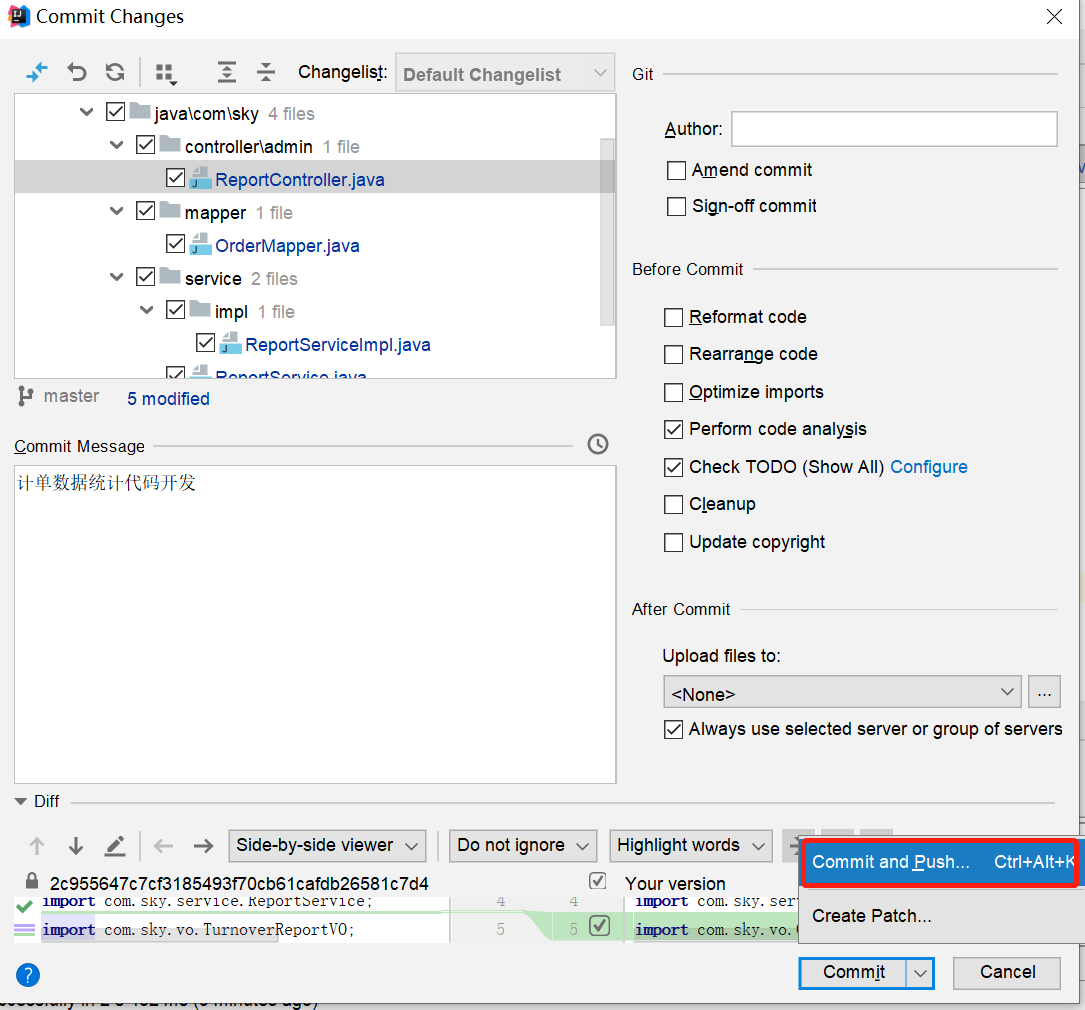 

后续步骤和其它功能代码提交一致，不再赘述。


### 订单统计提交前检查（补充）

确认统计日期字段、完成状态、完成率单位、零分母、空日期和状态常量都已固定，并将报表查询与订单写入事务解耦。


## 5. 销量排名Top10

> **PPT对照：** 第55—67页。


### 5.1 需求分析和设计

> **PPT对照：** 第57—58页。

#### 5.1.1 产品原型

所谓销量排名，销量指的是商品销售的数量。项目当中的商品主要包含两类：一个是**套餐**，一个是**菜品**，所以销量排名其实指的就是菜品和套餐销售的数量排名。通过柱形图来展示销量排名，这些销量是按照降序来排列，并且只需要统计销量排名前十的商品。

**原型图：**

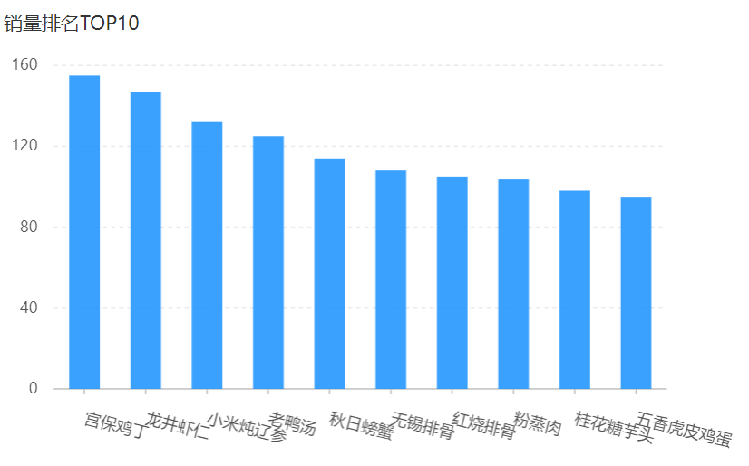 

**业务规则：**

- 根据时间选择区间，展示销量前10的商品（包括菜品和套餐）
- 基于可视化报表的柱状图降序展示商品销量
- 此处的销量为商品销售的份数


#### 5.1.2 接口设计

根据上述原型图设计接口。

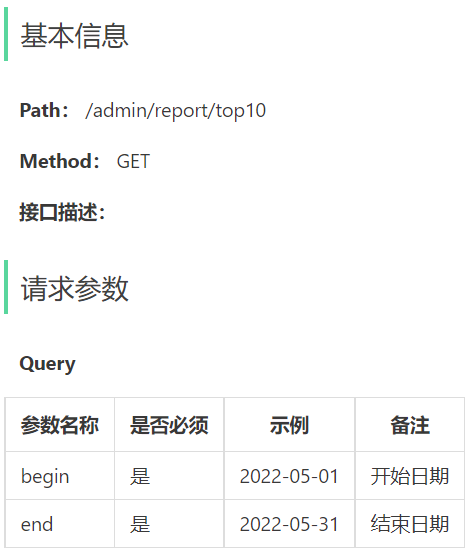 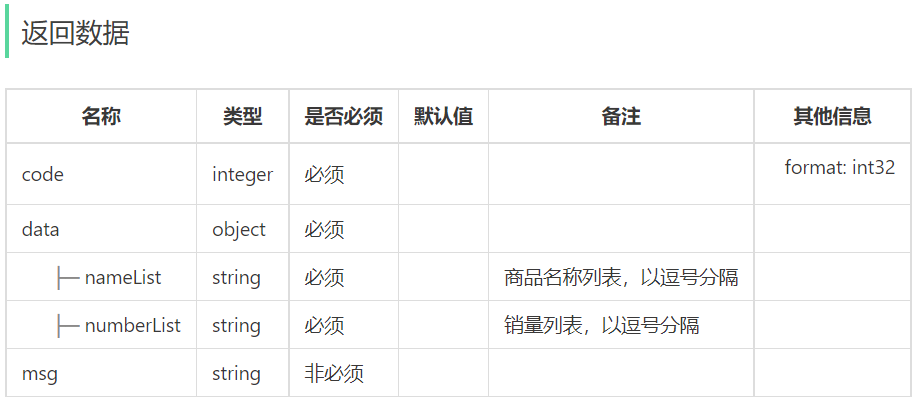


### 销量 Top10 的商品身份与口径（补充）

销量是已完成订单中商品明细数量之和，菜品和套餐都来自 `order_detail` 快照。统计时间字段仍需明确是下单时间还是完成时间；课程SQL使用 `orders.order_time`。

按商品id分组比按名称分组更可靠。同名菜品、改名商品或不同规格不能被错误合并；展示名称可以取订单明细中的快照名。并列第10名时是严格返回10条，还是扩展并列项，要写进产品规则。


### 5.2 代码开发

> **PPT对照：** 第60—65页。

#### 5.2.1 VO设计

**根据销量排名接口的返回结果设计VO：**

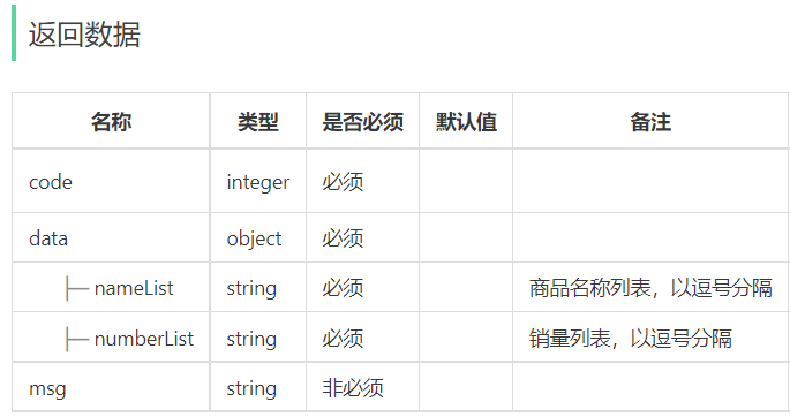 

在sky-pojo模块，SalesTop10ReportVO.java已定义

```java
package com.sky.vo;

import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class SalesTop10ReportVO implements Serializable {

    //商品名称列表，以逗号分隔，例如：鱼香肉丝,宫保鸡丁,水煮鱼
    private String nameList;

    //销量列表，以逗号分隔，例如：260,215,200
    private String numberList;

}
```


#### 5.2.2 Controller层

**在ReportController中根据销量排名接口创建top10方法：**

```java
/**
* 销量排名统计
* @param begin
* @param end
* @return
*/
@GetMapping("/top10")
@ApiOperation("销量排名统计")
public Result<SalesTop10ReportVO> top10(
    @DateTimeFormat(pattern = "yyyy-MM-dd") LocalDate begin,
    @DateTimeFormat(pattern = "yyyy-MM-dd") LocalDate end){
	return Result.success(reportService.getSalesTop10(begin,end));
}
```


#### 5.2.3 Service层接口

**在ReportService接口中声明getSalesTop10方法：**

```java
/**
* 查询指定时间区间内的销量排名top10 
* @param begin
* @param end
* @return
*/
SalesTop10ReportVO getSalesTop10(LocalDate begin, LocalDate end);
```


#### 5.2.4 Service层实现类

**在ReportServiceImpl实现类中实现getSalesTop10方法：**

```java
/**
     * 查询指定时间区间内的销量排名top10
     * @param begin
     * @param end
     * @return
     * */
    public SalesTop10ReportVO getSalesTop10(LocalDate begin, LocalDate end){
        LocalDateTime beginTime = LocalDateTime.of(begin, LocalTime.MIN);
        LocalDateTime endTime = LocalDateTime.of(end, LocalTime.MAX);
        List<GoodsSalesDTO> goodsSalesDTOList = orderMapper.getSalesTop10(beginTime, endTime);

        String nameList = StringUtils.join(goodsSalesDTOList.stream().map(GoodsSalesDTO::getName).collect(Collectors.toList()),",");
        String numberList = StringUtils.join(goodsSalesDTOList.stream().map(GoodsSalesDTO::getNumber).collect(Collectors.toList()),",");

        return SalesTop10ReportVO.builder()
                .nameList(nameList)
                .numberList(numberList)
                .build();
    }
```


#### 5.2.5 Mapper层

**在OrderMapper接口中声明getSalesTop10方法：**

```java
/**
* 查询商品销量排名
* @param begin
* @param end
*/
List<GoodsSalesDTO> getSalesTop10(LocalDateTime begin, LocalDateTime end);
```

**在OrderMapper.xml文件中编写动态SQL：**

```xml
<select id="getSalesTop10" resultType="com.sky.dto.GoodsSalesDTO">
        select od.name name,sum(od.number) number from order_detail od ,orders o
        where od.order_id = o.id
            and o.status = 5
            <if test="begin != null">
                and order_time &gt;= #{begin}
            </if>
            <if test="end != null">
                and order_time &lt;= #{end}
            </if>
        group by name
        order by number desc
        limit 0, 10
</select>
```


### Top10 SQL 的别名、空结果与排序（补充与勘误）

原SQL使用旧式逗号连接、`group by name` 和未限定的 `order_time`。建议改为显式 JOIN，并按稳定商品标识分组；如果明细没有商品id快照，至少确认同名合并是业务允许的。

```sql
select od.name,
       sum(od.number) as number
from order_detail od
join orders o on od.order_id = o.id
where o.status = 5
  and o.order_time >= #{begin}
  and o.order_time < #{endExclusive}
group by od.name
order by number desc, od.name asc
limit 10
```

实际SQL应根据数据库方言和商品id字段补充 `group by od.dish_id, od.setmeal_id, od.name` 等列。`limit 0,10` 是MySQL写法，迁移数据库时要调整。空结果应返回空数组/空字符串的明确契约，不能让前端对 null 做猜测。

服务层把结果映射为同长度的 nameList 和 numberList。销量数量使用 Long，避免 Integer 溢出；同一订单明细的快照名称可能不同，报表要决定按当前商品还是下单时名称展示。


### 5.3 功能测试

> **PPT对照：** 第67页。

可以通过如下方式进行测试：

- 接口文档测试
- 前后端联调

重启服务，直接采用前后端联调测试。

**查看近30日销量排名Top10统计**

若查询的某一段时间没有销量数据，则显示不出效果。

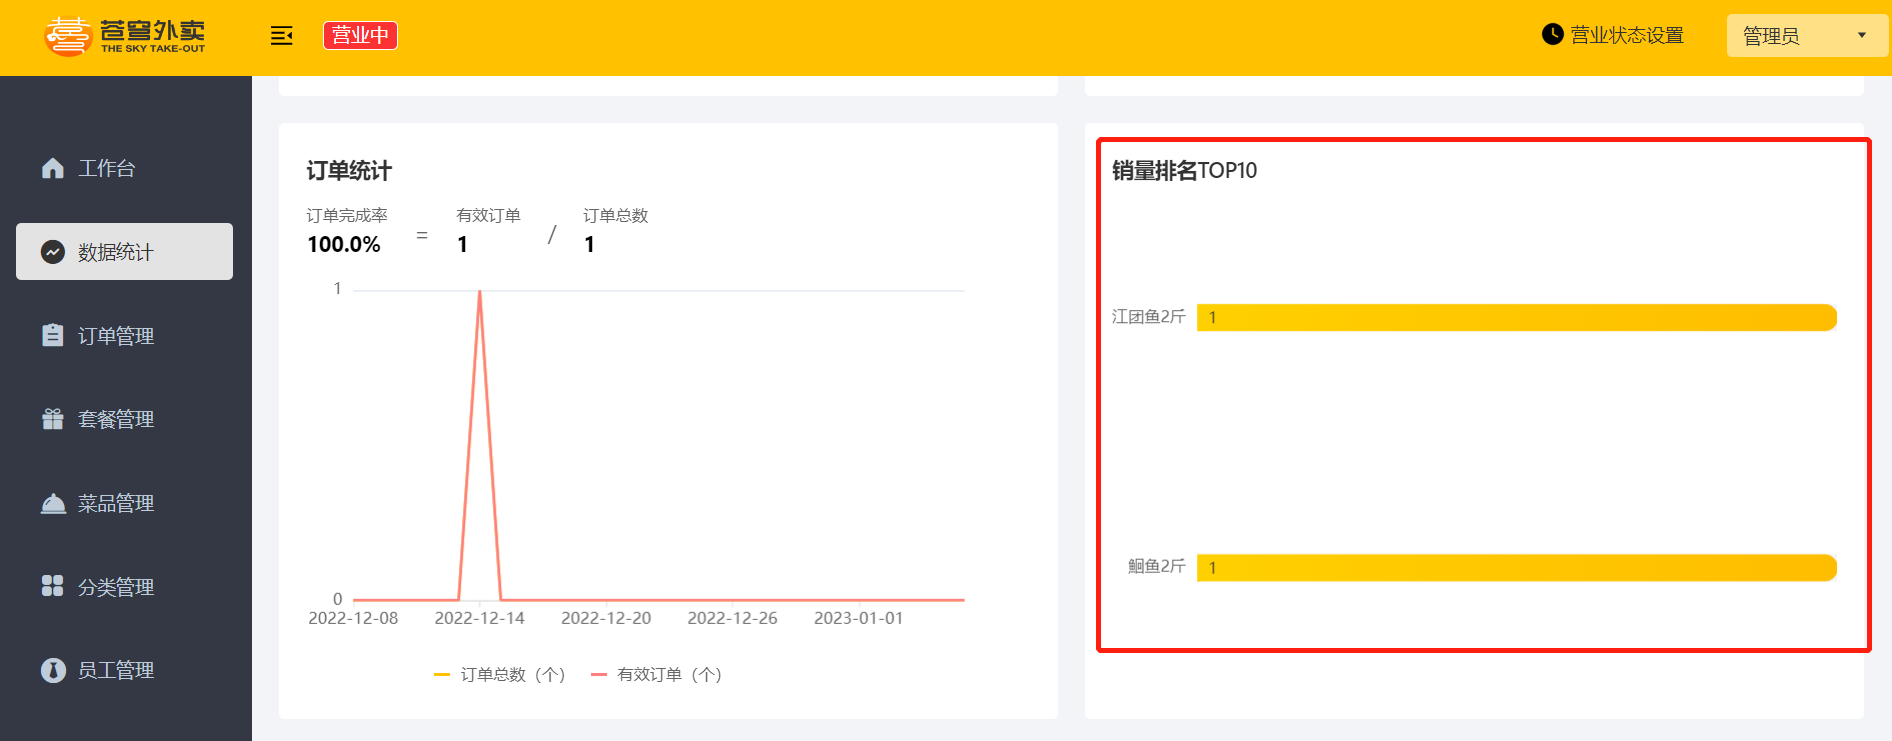 

进入开发者模式，查看返回数据

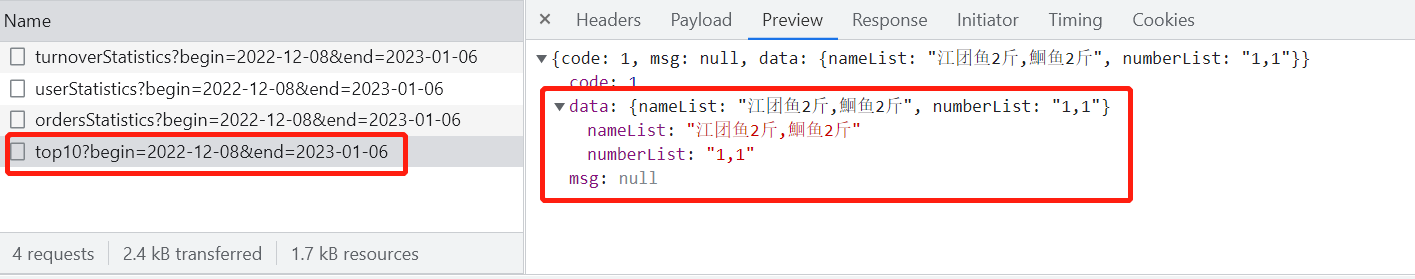 

也可通过断点方式启动，查看每步执行情况。


### 销量 Top10 验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 有已完成订单明细 | 按数量降序返回最多10项 |
| 取消或未完成订单 | 不计入销量 |
| 同名不同商品 | 按产品定义区分或合并，结果稳定 |
| 销量相同 | 使用稳定的二级排序 |
| 少于10项或无数据 | 返回实际数量，前端不报错 |
| 跨日期边界 | 按统一统计时间字段筛选 |
| 大量明细 | 有连接、状态和时间索引，查询可控 |

核对SQL原始结果、商品名称与数量数组长度，并用一个已知订单手算验证。


### 5.4 代码提交

> **PPT对照：** 课程提交页。

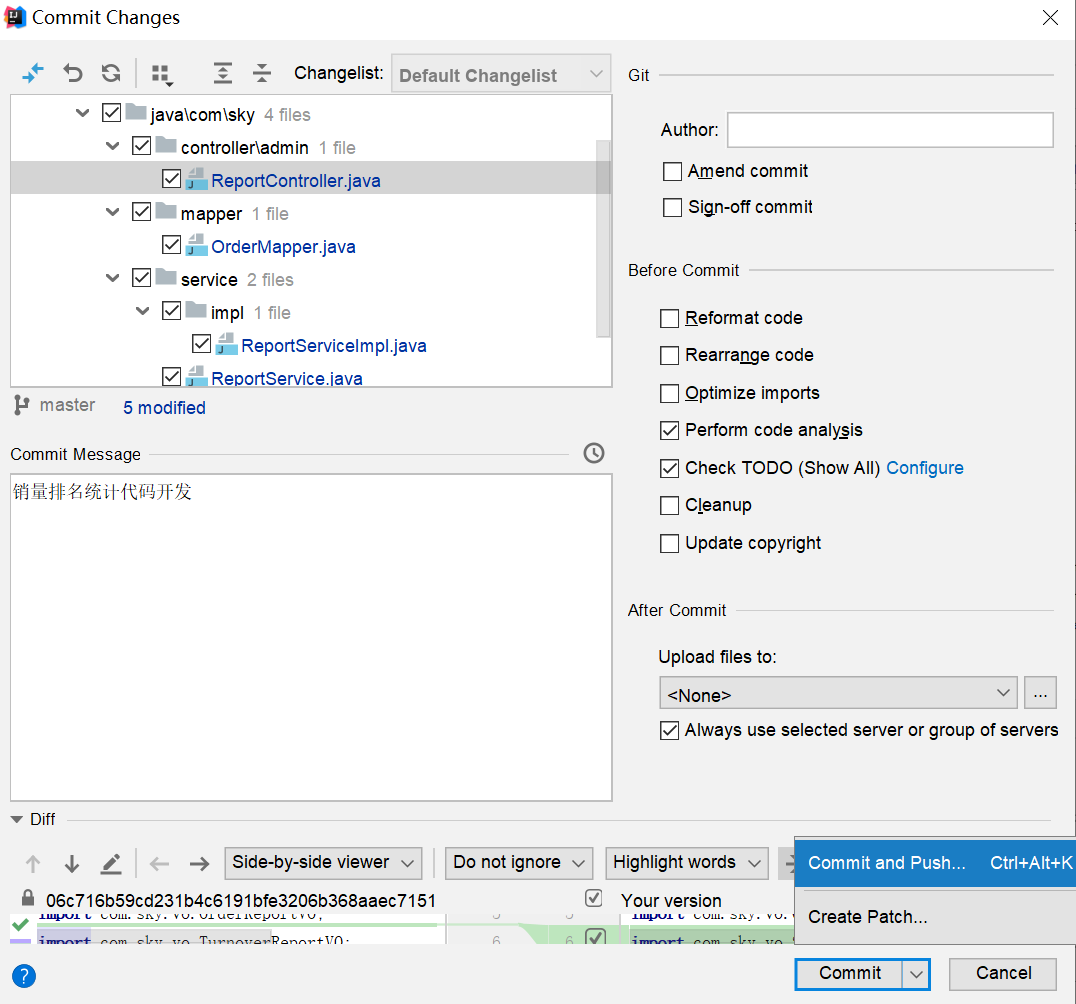 

后续步骤和其它功能代码提交一致，不再赘述。


### Top10 提交前检查（补充）

确认商品身份、统计时间字段、完成状态、并列排序、Long计数、空结果和数据库方言已固定；前端柱状图的 name/value 顺序要与接口契约一致。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| ECharts | 图表只负责展示，统计口径由后端和产品定义 |
| 日期范围 | 校验 begin/end，建议使用半开区间和统一时区 |
| 营业额 | 已完成订单金额，金额用 BigDecimal，空日补0 |
| 用户统计 | 新增按 create_time，总量是截至当天的累计或快照 |
| 订单统计 | 总订单、有效订单和完成率分母要明确 |
| 完成率 | 分母为0返回0，比例或百分比单位写入契约 |
| Top10 | 已完成订单明细按稳定商品身份聚合和排序 |
| 性能 | 按天循环查询是 N+1，大范围报表应一次聚合或离线汇总 |
| 权限 | 报表接口仅管理员可访问，查询不修改业务数据 |

### 跟练验收清单

- [ ] 四个报表接口都校验日期范围、最大跨度和权限。
- [ ] 日期轴完整，空日期数据为0，所有 series 长度一致。
- [ ] 金额使用正确精度，营业额状态与财务口径一致。
- [ ] 用户新增和总量的时间边界、账号范围和时区明确。
- [ ] 订单总数、有效数、完成率的日期字段和单位明确。
- [ ] 完成率分母为0不会产生 NaN 或 Infinity。
- [ ] Top10 不错误合并同名商品，排序和并列规则稳定。
- [ ] 报表查询有索引和性能策略，避免大范围 N+1 查询。
- [ ] 接口空结果、数据库异常和前端图表错误都有可观察日志。

### 自测问题

1. ECharts option 中的日期和 series 数据为什么必须等长？
2. 为什么营业额金额不建议用 Double？
3. 日期查询使用 `LocalTime.MAX` 有哪些边界风险？
4. 按天循环执行统计SQL会产生什么性能问题？
5. 用户总量与新增量分别使用什么时间口径？
6. 订单完成率分母为0时接口应该返回什么？
7. 订单统计按下单日和按完成日有什么业务差异？
8. 为什么 Top10 按商品名称分组可能错误合并商品？
9. Top10 销量相同为什么需要二级排序？
10. 报表接口为什么需要管理员权限和最大日期跨度？

本章的图形只是统计结果的呈现，最终应以明确的SQL口径、数据库数据和接口契约共同验证。
